# General Imports

In [1]:
import os 
import kagglehub

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.pandas.set_option('display.max_columns', None)
pd.pandas.set_option('display.max_rows', None)

import scipy.stats as stats

from sklearn.preprocessing import MinMaxScaler

from sklearn.model_selection import train_test_split

In [2]:
path = kagglehub.competition_download('house-prices-advanced-regression-techniques')
print("Ścieżka do plików:", path)

data = pd.read_csv(os.path.join(path, 'train.csv'))
data.head()

Ścieżka do plików: /kaggle/input/competitions/house-prices-advanced-regression-techniques


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
data.drop(columns=['Id'],inplace=True)
data.shape

(1460, 80)

# EDA
Before examining individual variables, I first take a brief look at the overall structure of the dataset. The predictors are divided into numerical and categorical features, as these groups will require different approaches during further exploration and preprocessing.

In [117]:
missing_ratio = (
    data.isnull()
        .mean()
        .sort_values(ascending=False)
)

missing_ratio = missing_ratio[missing_ratio > 0]

print(f'Features with missing values: {len(missing_ratio)}')
print(f'Features without missing values: {data.shape[1] - len(missing_ratio)}')

Features with missing values: 19
Features without missing values: 61


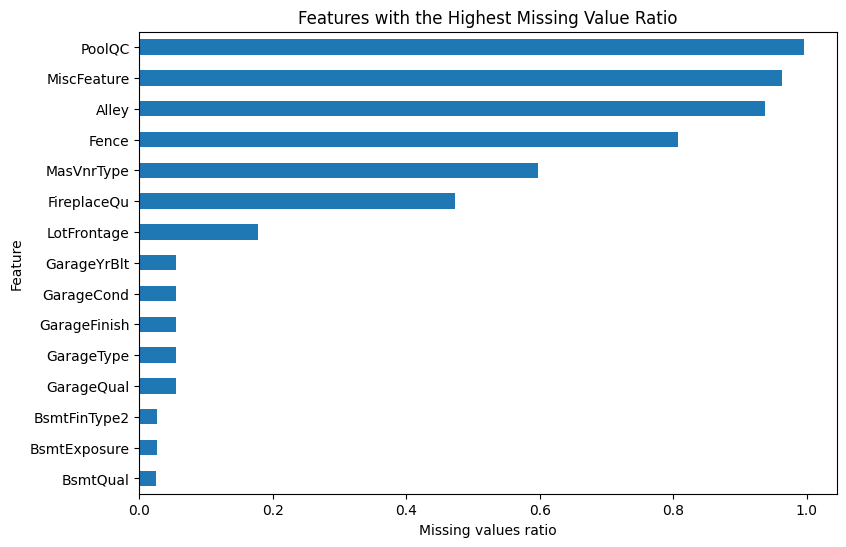

In [118]:
plt.figure(figsize=(9, 6))

missing_ratio.head(15).sort_values().plot(kind='barh')

plt.xlabel('Missing values ratio')
plt.ylabel('Feature')
plt.title('Features with the Highest Missing Value Ratio')

plt.show()

In [4]:
numerical_features = [
    var for var in data.select_dtypes(include=np.number).columns
    if var not in ['SalePrice', 'MSSubClass']
]

categorical_features = (
    data.select_dtypes(exclude=np.number).columns.tolist()
    + ['MSSubClass']
)

print(f'Numerical features: {len(numerical_features)}')
print(f'Categorical features: {len(categorical_features)}')
print(f'Total predictors: {len(numerical_features) + len(categorical_features)}')

Numerical features: 35
Categorical features: 44
Total predictors: 79


## Initial Correlation Overview

To obtain a quick overview of the numerical relationships in the dataset, I examine the variables most strongly correlated with `SalePrice`. This is only an initial exploratory step — a more comprehensive feature selection procedure will be performed later using multiple statistical measures and redundancy analysis.

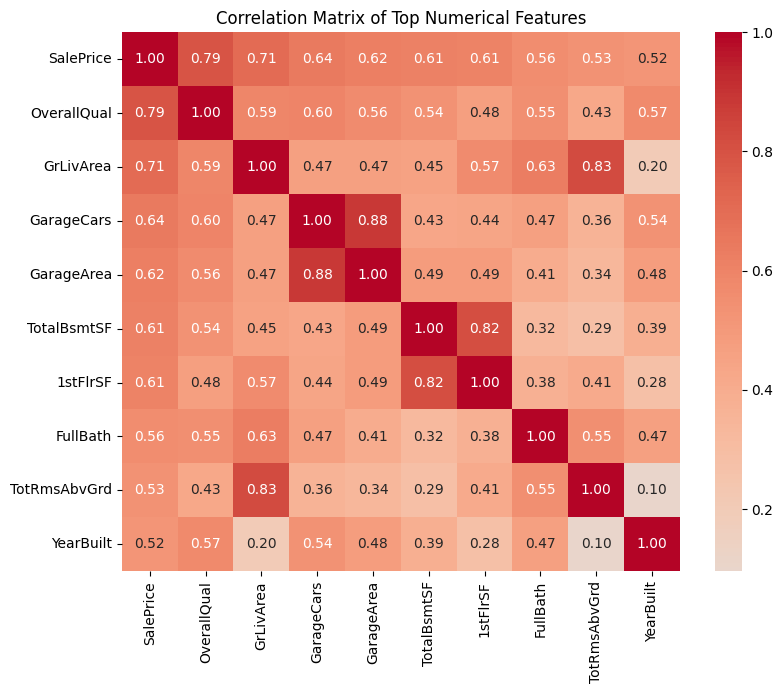

In [5]:
correlations = (
    data[numerical_features + ['SalePrice']]
    .corr()['SalePrice']
    .abs()
    .sort_values(ascending=False)
)

top_corr_features = correlations.head(10).index

plt.figure(figsize=(9, 7))

sns.heatmap(
    data[top_corr_features].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix of Top Numerical Features')
plt.show()

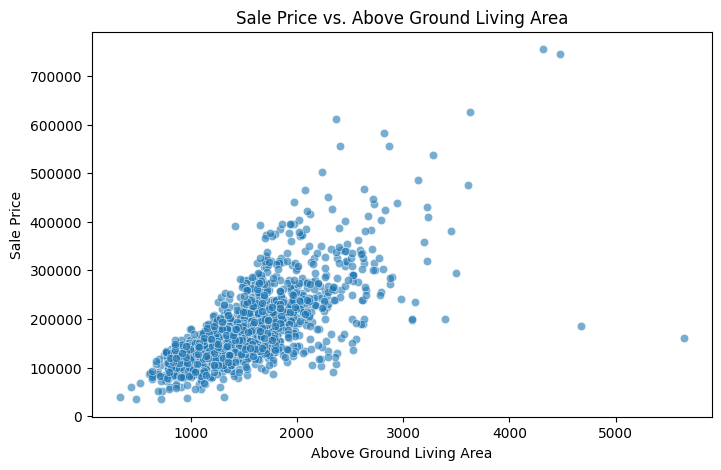

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x='GrLivArea',
    y='SalePrice',
    alpha=0.6
)

plt.title('Sale Price vs. Above Ground Living Area')
plt.xlabel('Above Ground Living Area')
plt.ylabel('Sale Price')

plt.show()

Initial observations: OverallQual and GrLivArea show the strongest linear relationships with SalePrice among the selected numerical features. The scatter plot confirms a clear positive relationship between living area and sale price, while also showing several atypical observations. Strong correlations between some predictors also suggest possible feature redundancy, which will be investigated later during feature selection.

# Train/test split

When we engineer features, some techniques learn parameters from data. It is important to learn these parameters only from the train set. This is to avoid over-fitting. Let's separate into train and test set

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    data.drop(['SalePrice'], axis=1),
    data['SalePrice'],
    test_size=0.1,
    random_state=0,
)

X_train.shape, X_test.shape

((1314, 79), (146, 79))

# Target

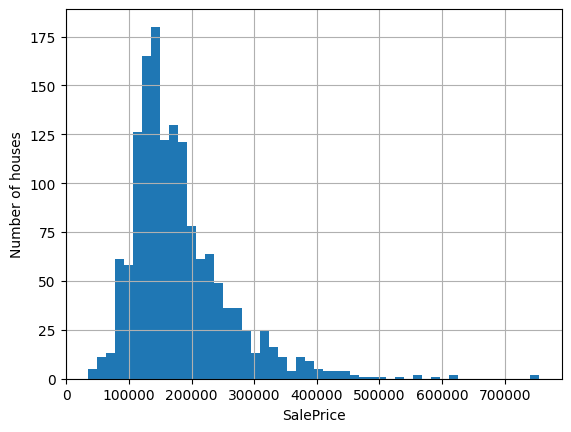

In [8]:
data['SalePrice'].hist(bins=50)
plt.ylabel('Number of houses')
plt.xlabel('SalePrice')
plt.show()

The target is continuous, and the distribution is skewed towards the right.

I will improve the value spread with a mathematical log
transformation.

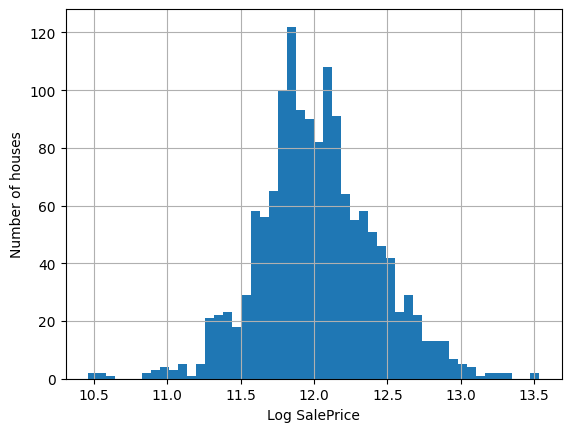

In [9]:
np.log(data['SalePrice']).hist(bins=50)
plt.ylabel('Number of houses')
plt.xlabel('Log SalePrice')
plt.show()

Now the distribution looks more Gaussian.

In [10]:
y_train = np.log(y_train)
y_test = np.log(y_test)

# Missing values

In [11]:
vars_with_na = [var for var in data.columns if data[var].isna().sum()>0]

missing_ratio = data[vars_with_na].isnull().mean().sort_values(ascending=False)
missing_ratio.name=""
missing_ratio

PoolQC          0.995205
MiscFeature     0.963014
Alley           0.937671
Fence           0.807534
MasVnrType      0.597260
FireplaceQu     0.472603
LotFrontage     0.177397
GarageType      0.055479
GarageYrBlt     0.055479
GarageFinish    0.055479
GarageQual      0.055479
GarageCond      0.055479
BsmtExposure    0.026027
BsmtFinType2    0.026027
BsmtQual        0.025342
BsmtCond        0.025342
BsmtFinType1    0.025342
MasVnrArea      0.005479
Electrical      0.000685
Name: , dtype: float64

Dataset contains 4 variables with a big proportion of missing values, 2 variables with moderate and others with a small percentage of missing observations.

Let's see how missings affect on target.

In [12]:
def analyze_missing_value(df, var):
  df = df.copy()

  df[var] = np.where(df[var].isnull(),1,0)

  tmp = df.groupby(var)['SalePrice'].agg(['mean', 'std'])

  tmp.plot(kind='barh', y='mean', xerr='std', title='Sales Price', legend=False)

  plt.show()

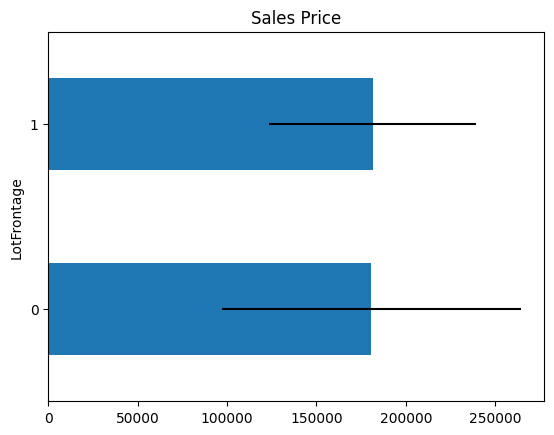

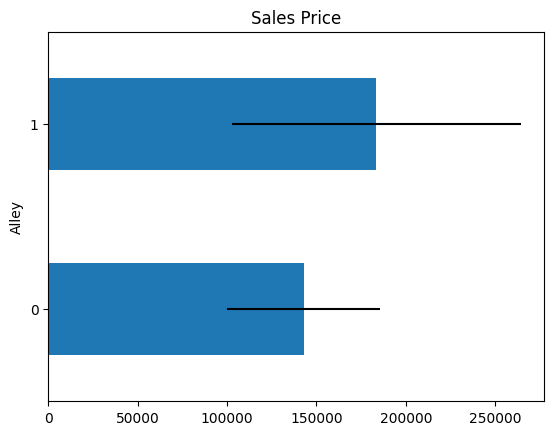

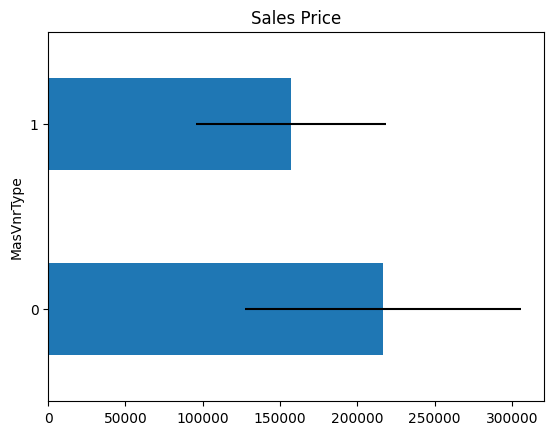

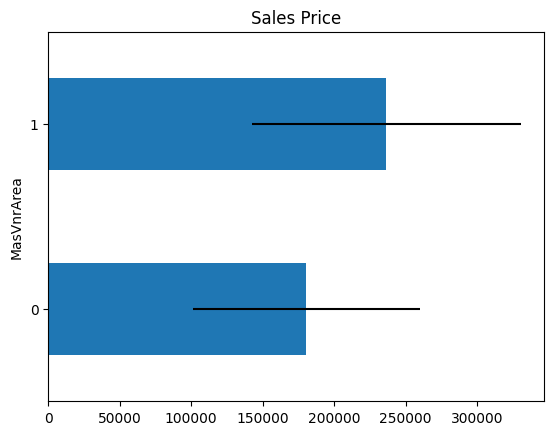

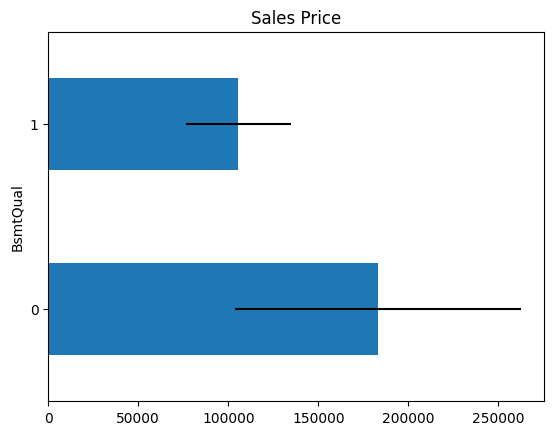

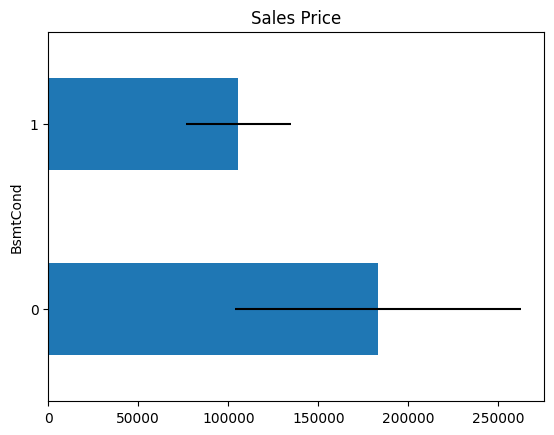

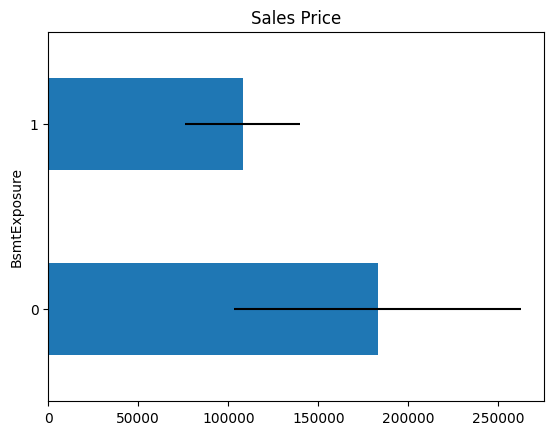

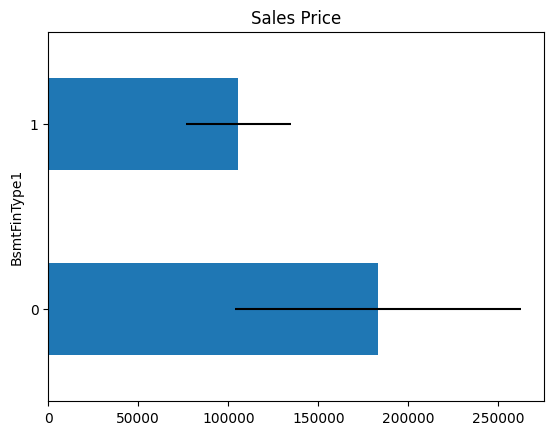

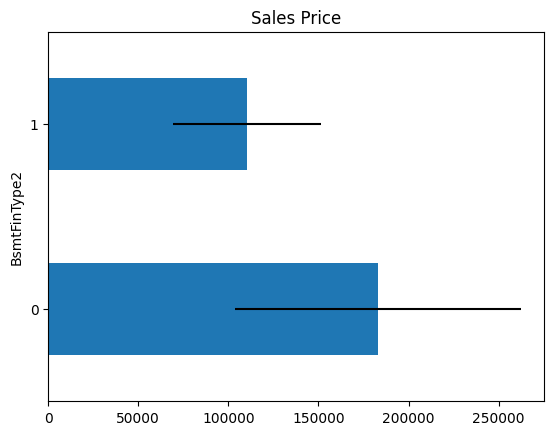

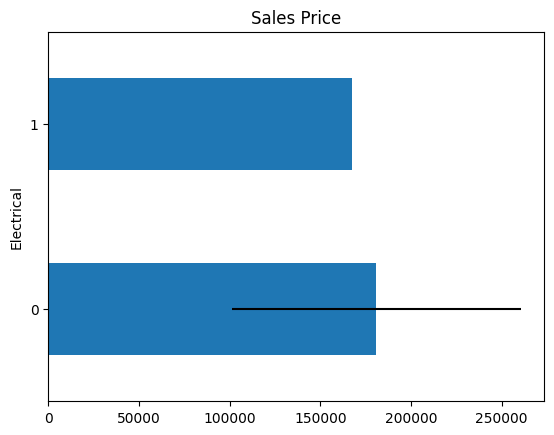

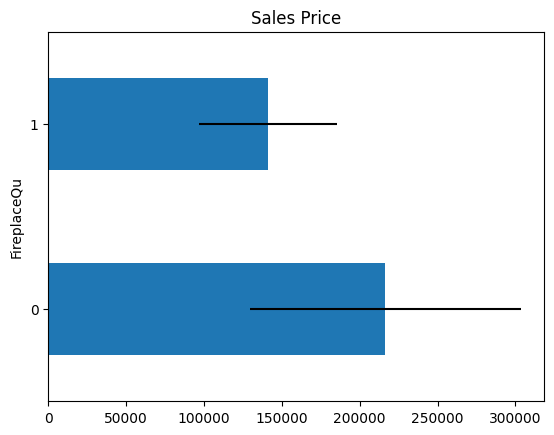

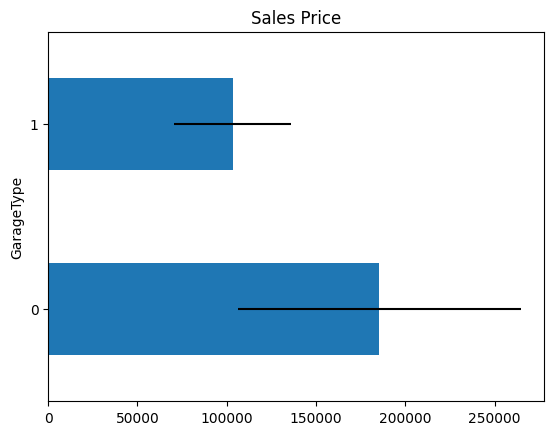

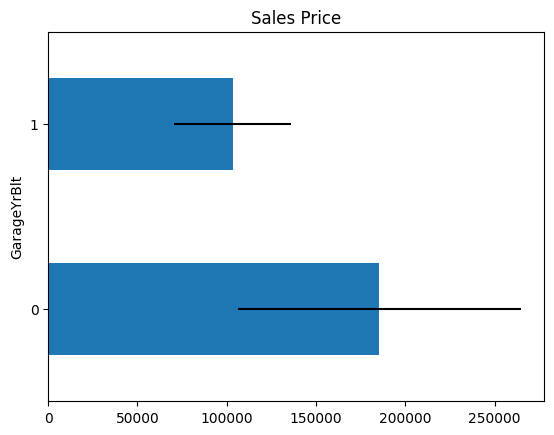

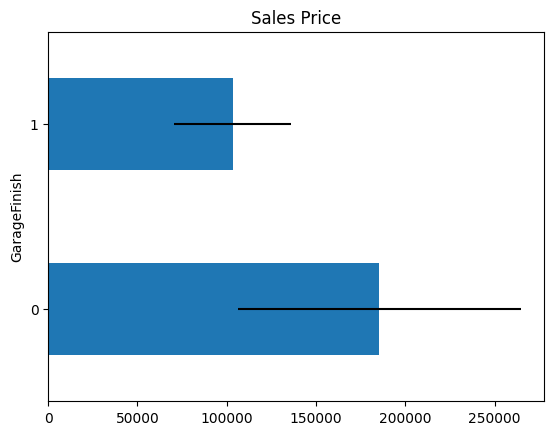

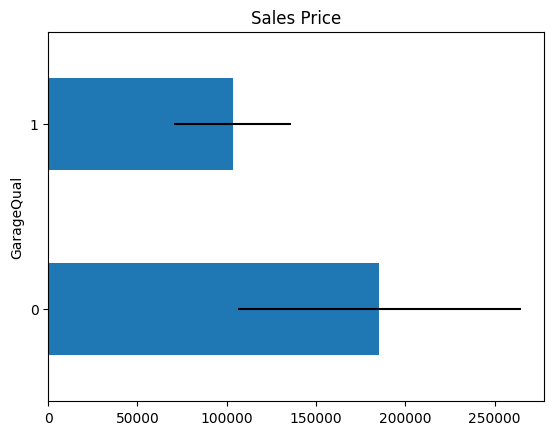

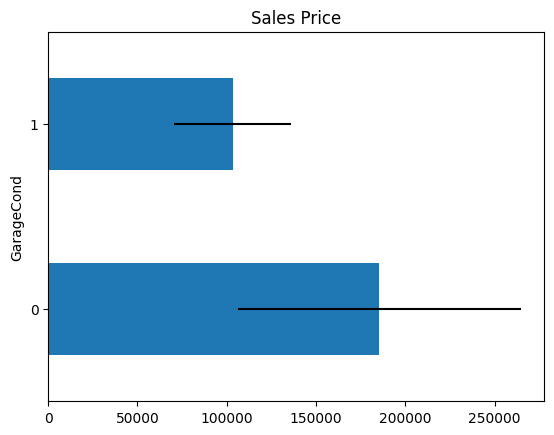

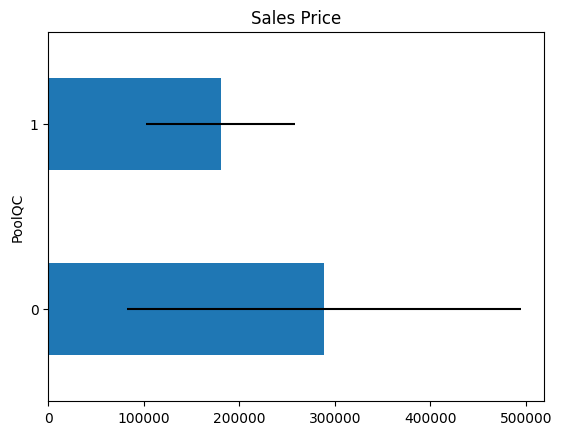

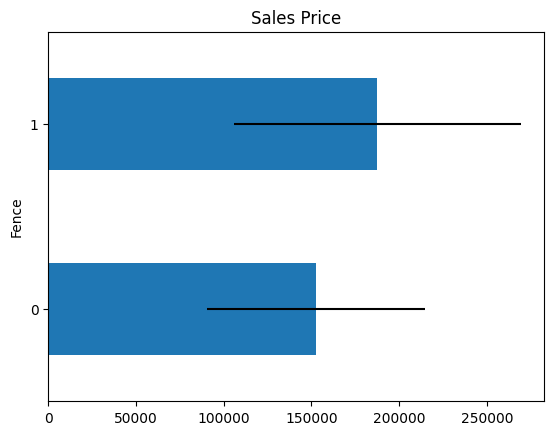

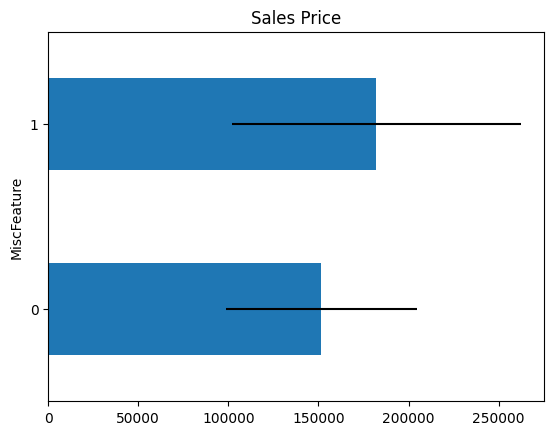

In [13]:
for var in vars_with_na:
  analyze_missing_value(data, var)

With the exception of LotFrontage and Electrical, the average Sale Price in houses where the information is missing differs from the average Sale Price in houses where information is not missing. So it suggest that data being missing may be a good predictor of Sale Price.

## Missing imputation

### Categorical

In [14]:
cat_vars_with_na = [var for var in vars_with_na if data[var].dtypes=='O']

In [15]:
with_string_missing = [
    var for var in cat_vars_with_na if X_train[var].isnull().mean()>0.1
]

with_frequent_category = [
    var for var in cat_vars_with_na if X_train[var].isnull().mean()<=0.1
]

In [16]:
with_string_missing

['Alley', 'MasVnrType', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']

In [17]:
with_frequent_category

['BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Electrical',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond']

In [18]:
X_train[with_string_missing] = X_train[with_string_missing].fillna('Missing')
X_test[with_string_missing] = X_test[with_string_missing].fillna('Missing')

In [19]:
for var in with_frequent_category:
    mode = X_train[var].mode()[0]

    X_train[var] = X_train[var].fillna(mode)
    X_test[var] = X_test[var].fillna(mode)

In [20]:
X_train[cat_vars_with_na].isnull().sum()

Alley           0
MasVnrType      0
BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
Electrical      0
FireplaceQu     0
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
PoolQC          0
Fence           0
MiscFeature     0
dtype: int64

In [21]:
X_test[cat_vars_with_na].isnull().sum()

Alley           0
MasVnrType      0
BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
Electrical      0
FireplaceQu     0
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
PoolQC          0
Fence           0
MiscFeature     0
dtype: int64

### Numerical

In [22]:
num_vars_with_na = [var for var in vars_with_na if var not in cat_vars_with_na and var!='SalePrice']

In [23]:
for var in num_vars_with_na:
  mean_val = X_train[var].mean()

  X_train[var] = X_train[var].fillna(mean_val)
  X_test[var] = X_test[var].fillna(mean_val)

In [24]:
X_train[num_vars_with_na].isnull().sum()

LotFrontage    0
MasVnrArea     0
GarageYrBlt    0
dtype: int64

In [25]:
X_test[num_vars_with_na].isnull().sum()

LotFrontage    0
MasVnrArea     0
GarageYrBlt    0
dtype: int64

# Numerical variable

In [26]:
num_vars = [var for var in data.columns if data[var].dtypes!='O' and var!='SalePrice' and var!='MSSubClass']
data[num_vars].head()

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
0,65.0,8450,7,5,2003,2003,196.0,706,0,150,856,856,854,0,1710,1,0,2,1,3,1,8,0,2003.0,2,548,0,61,0,0,0,0,0,2,2008
1,80.0,9600,6,8,1976,1976,0.0,978,0,284,1262,1262,0,0,1262,0,1,2,0,3,1,6,1,1976.0,2,460,298,0,0,0,0,0,0,5,2007
2,68.0,11250,7,5,2001,2002,162.0,486,0,434,920,920,866,0,1786,1,0,2,1,3,1,6,1,2001.0,2,608,0,42,0,0,0,0,0,9,2008
3,60.0,9550,7,5,1915,1970,0.0,216,0,540,756,961,756,0,1717,1,0,1,0,3,1,7,1,1998.0,3,642,0,35,272,0,0,0,0,2,2006
4,84.0,14260,8,5,2000,2000,350.0,655,0,490,1145,1145,1053,0,2198,1,0,2,1,4,1,9,1,2000.0,3,836,192,84,0,0,0,0,0,12,2008


## Discrete variables


In [27]:
discrete_vars = [var for var in num_vars if len(data[var].unique())<20 and var not in ['MSSubClass', 'YearBuilt', 'YearRemodAdd', 'YrSold', 'GarageYrBlt']]
discrete_vars

['OverallQual',
 'OverallCond',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageCars',
 'PoolArea',
 'MoSold']

These discrete variables tend to be qualifications (Qual) or grading scales (Cond), or refer to the number of rooms, or units (FullBath, GarageCars), or indicate the area of the room (KitchenAbvGr).

We expect higher prices, with bigger numbers.

Let's go ahead and analyse their contribution to the house price.

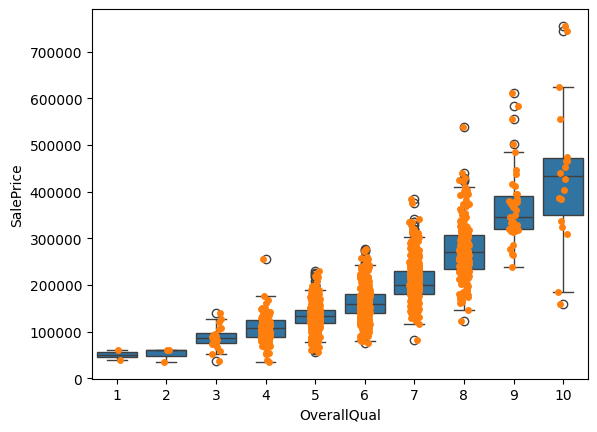

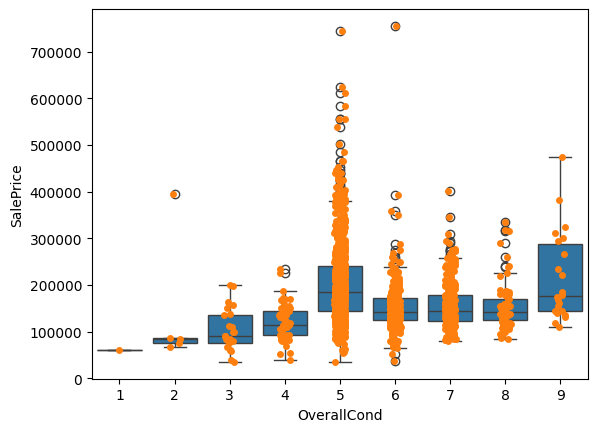

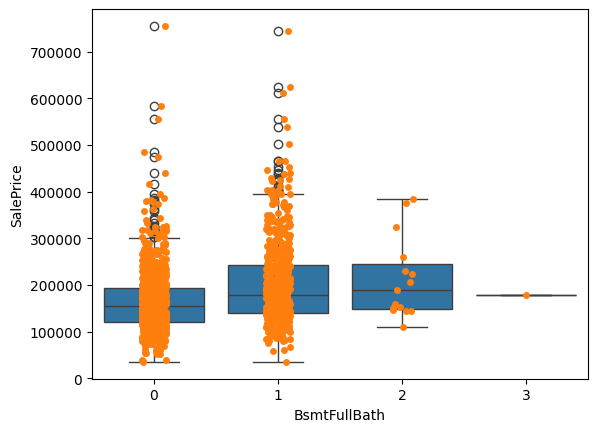

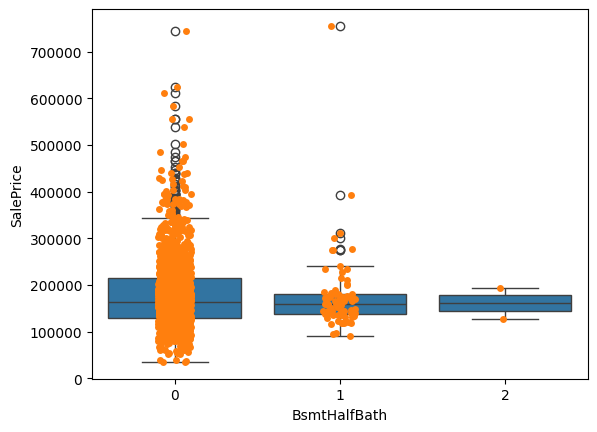

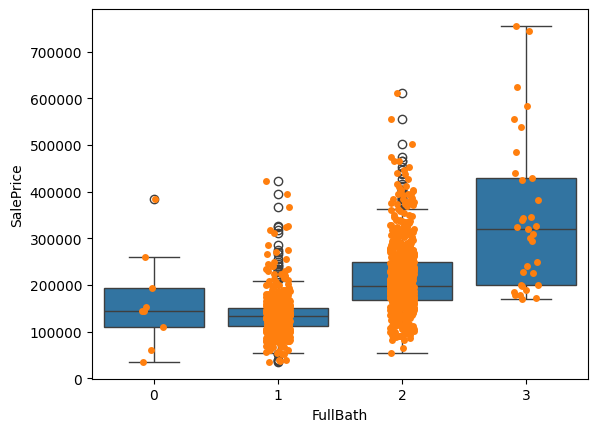

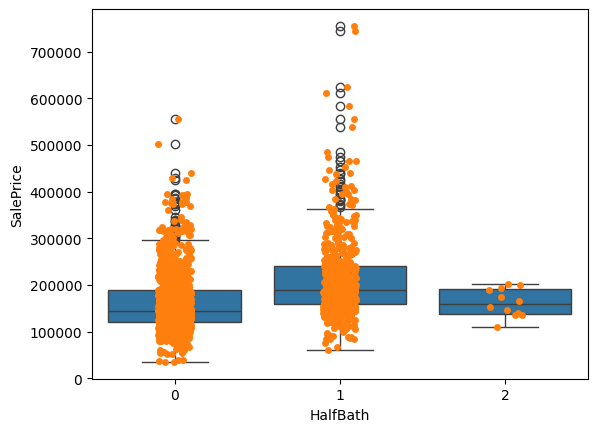

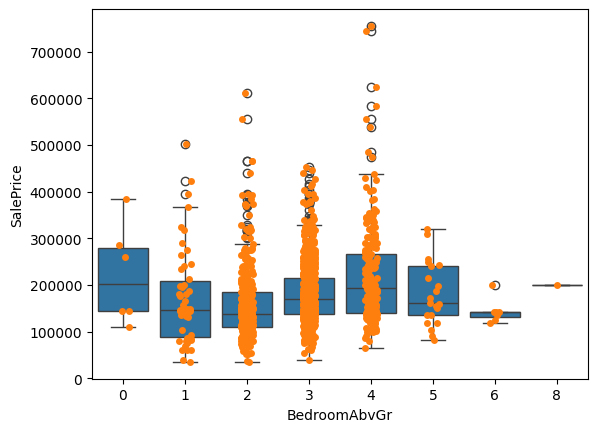

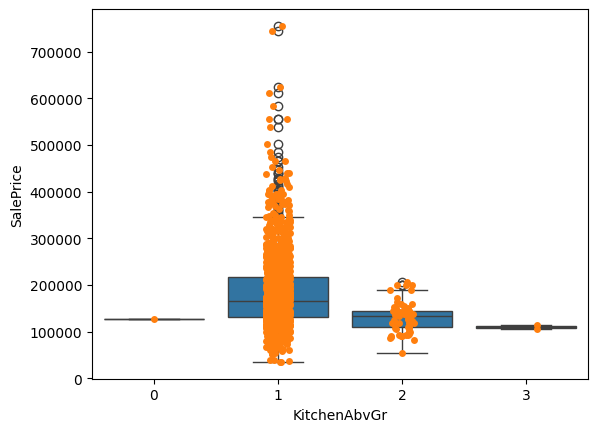

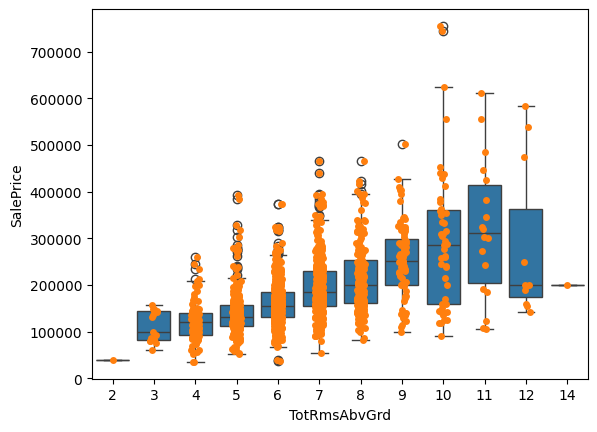

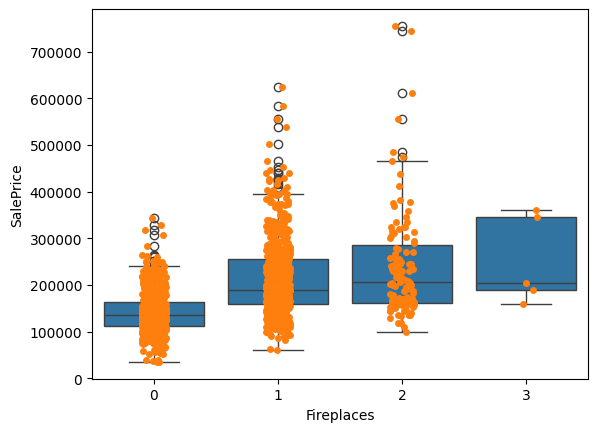

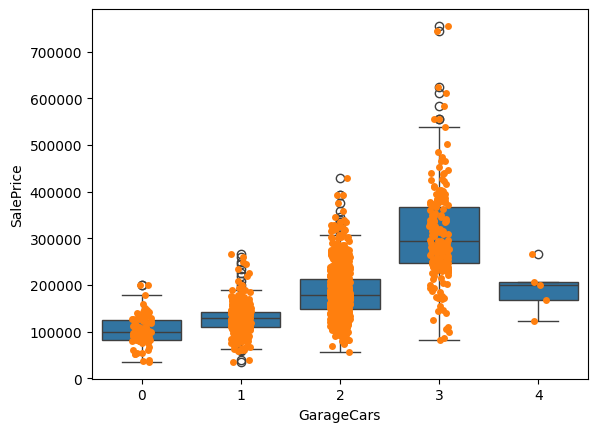

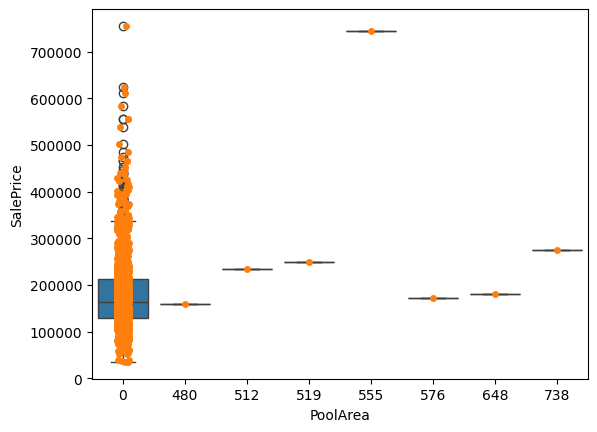

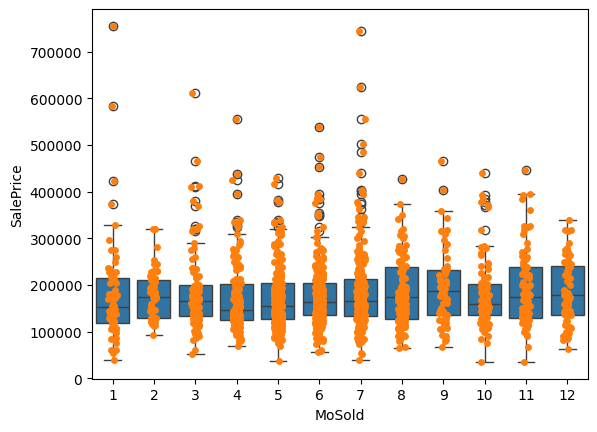

In [28]:
for var in discrete_vars:
  sns.boxplot(data=data, x=var, y='SalePrice')
  sns.stripplot(x=var, y='SalePrice', data=data)

  plt.show()

For variables like OverallQual,OverallCond,FullBath,GarageCars,KitchenAbvGr,TotRmsAbvGrd,Fireplaces and GarageCars we see an increase in the sale price, with the quality, or overall condition, or number of rooms etc.

For the remaining variables, we do not observe this trend. Therefore, they are not good predictors of the selling price.

## Continuous variables


In [29]:
cont_vars = [var for var in num_vars if var not in discrete_vars and var not in ['MSSubClass', 'YearBuilt', 'YearRemodAdd', 'YrSold', 'GarageYrBlt']]
cont_vars

['LotFrontage',
 'LotArea',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'MiscVal']

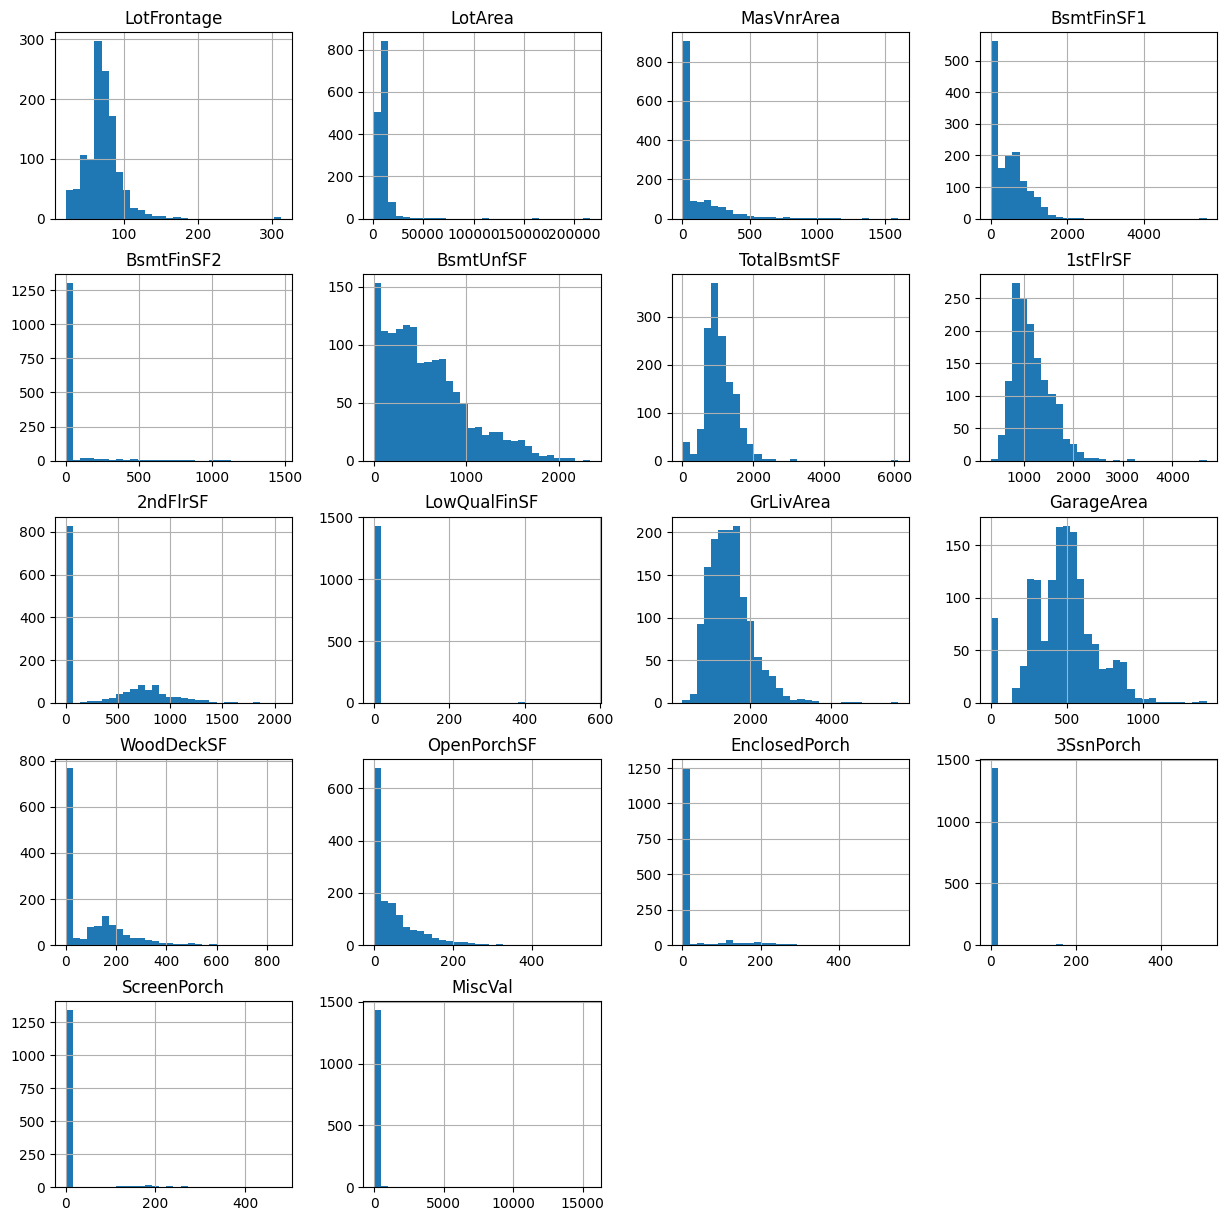

In [30]:
data[cont_vars].hist(bins=30, figsize=(15,15))
plt.show()

In [31]:
skewed = [
    'BsmtFinSF2', 'LowQualFinSF', 'EnclosedPorch',
    '3SsnPorch', 'ScreenPorch', 'MiscVal'
]

cont_vars = [
    'LotFrontage',
    'LotArea',
    'MasVnrArea',
    'BsmtFinSF1',
    'BsmtUnfSF',
    'TotalBsmtSF',
    '1stFlrSF',
    '2ndFlrSF',
    'GrLivArea',
    'GarageArea',
    'WoodDeckSF',
    'OpenPorchSF',
]

For skewed variables, I use a binary transformation, for the others, logarithmic transformation.

In [32]:
for var in skewed:
    X_train[var] = np.where(X_train[var]==0, 0, 1)
    X_test[var] = np.where(X_test[var]==0, 0, 1)

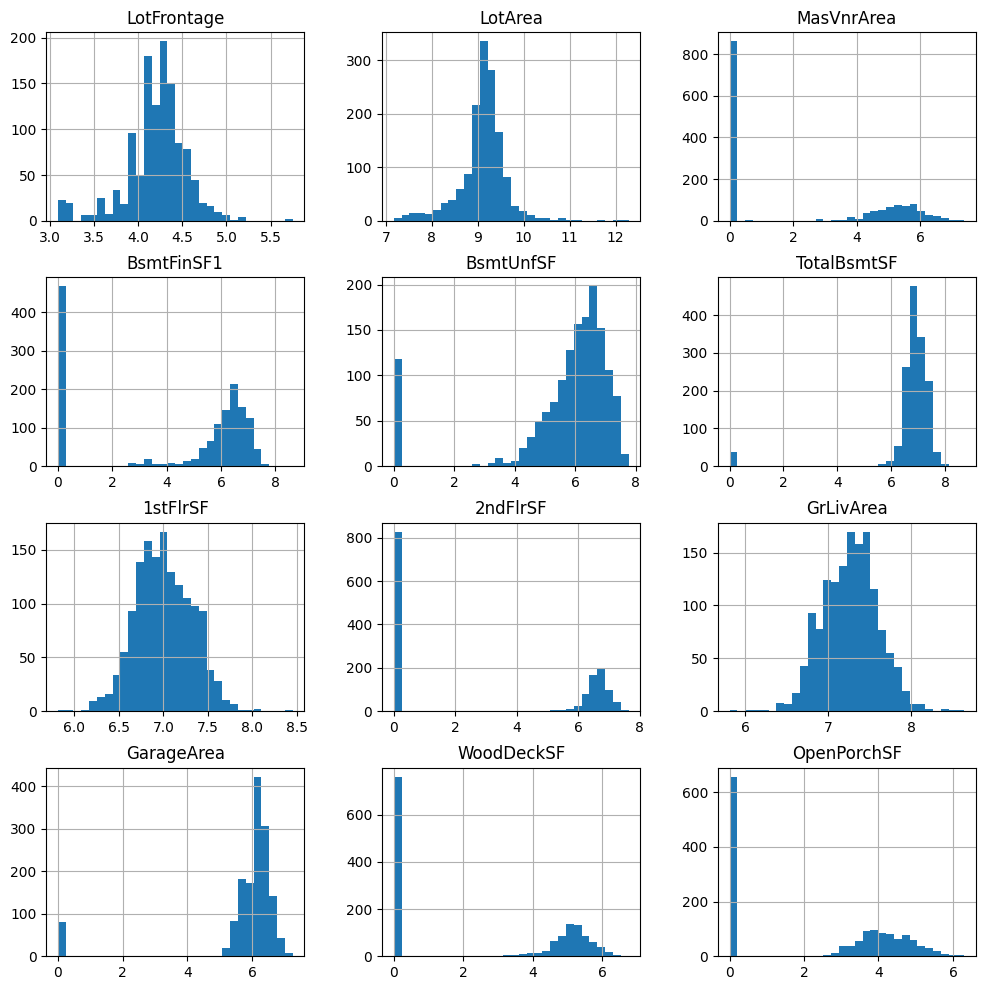

In [33]:
tmp = data.copy()
for var in cont_vars:
  tmp[var] = np.log1p(tmp[var])

tmp[cont_vars].hist(bins=30, figsize=(12,12))
plt.show()


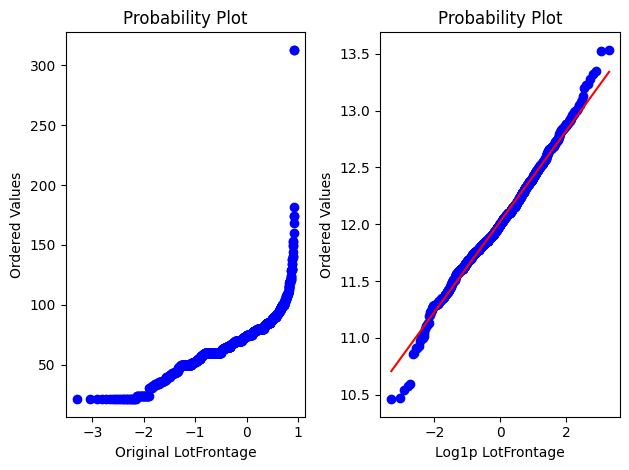

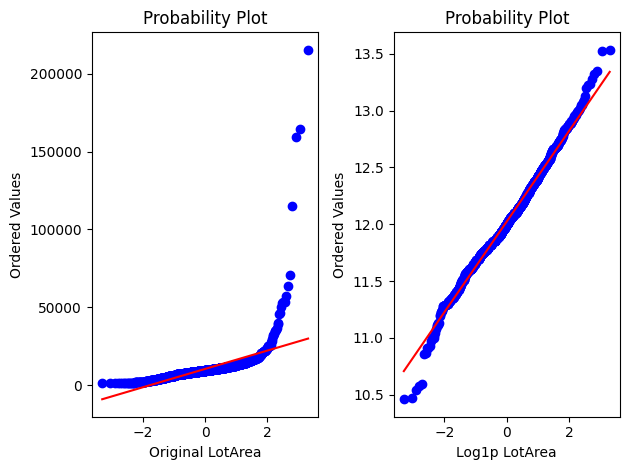

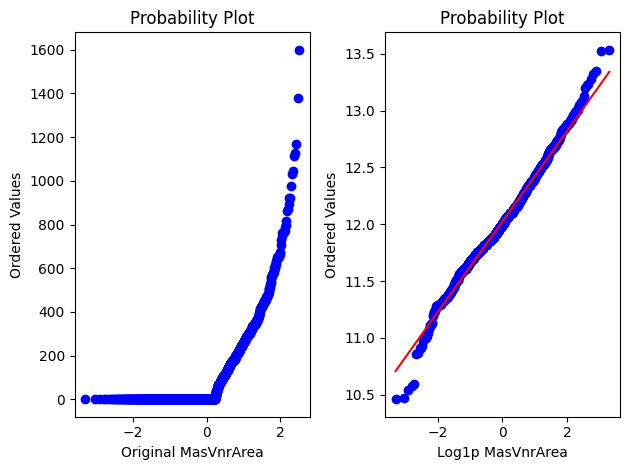

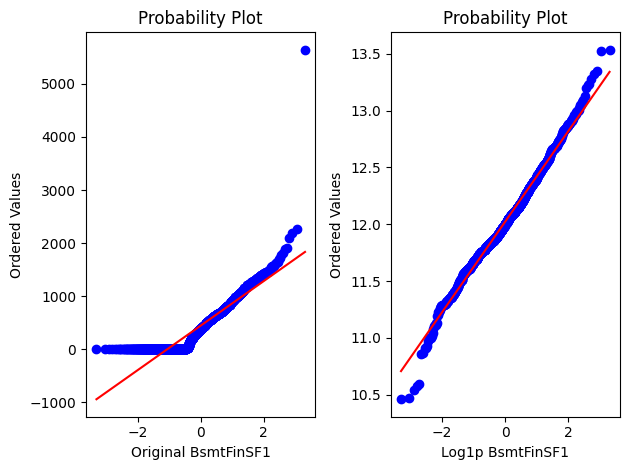

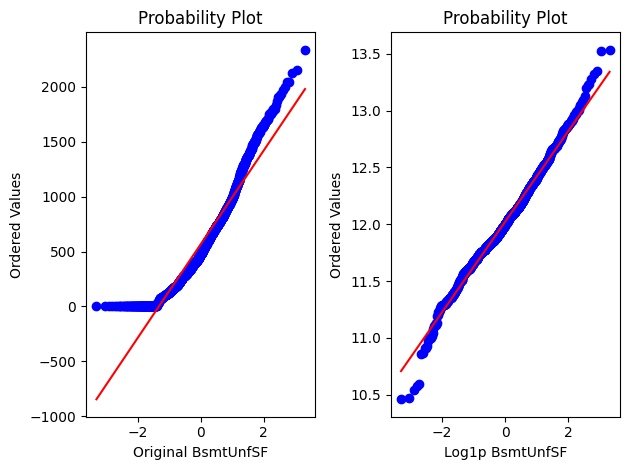

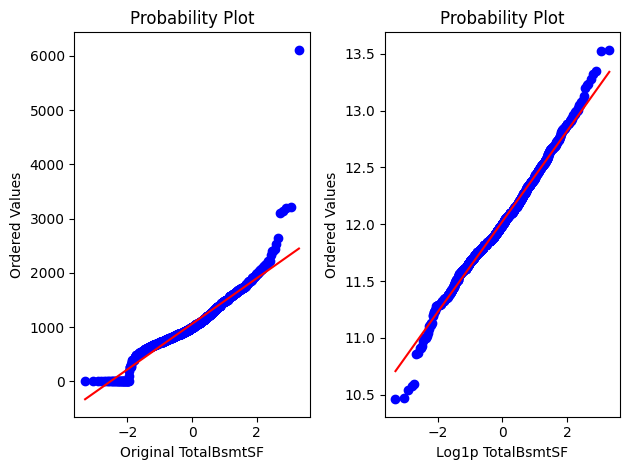

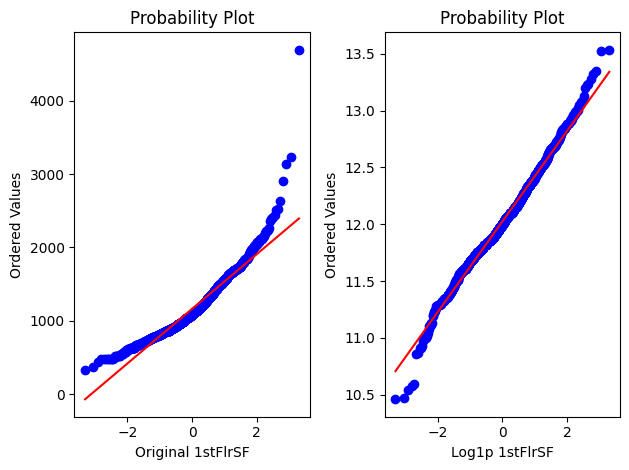

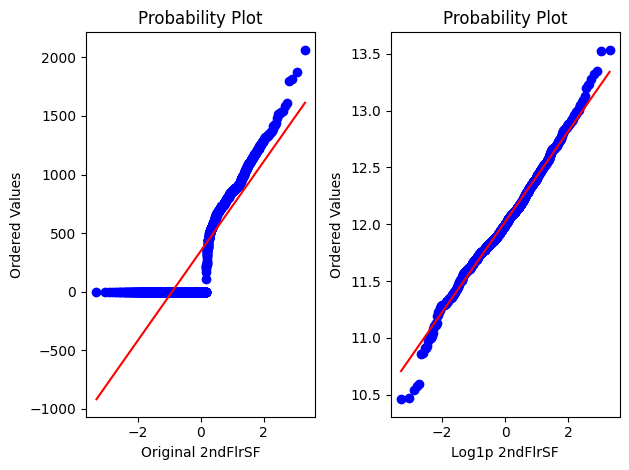

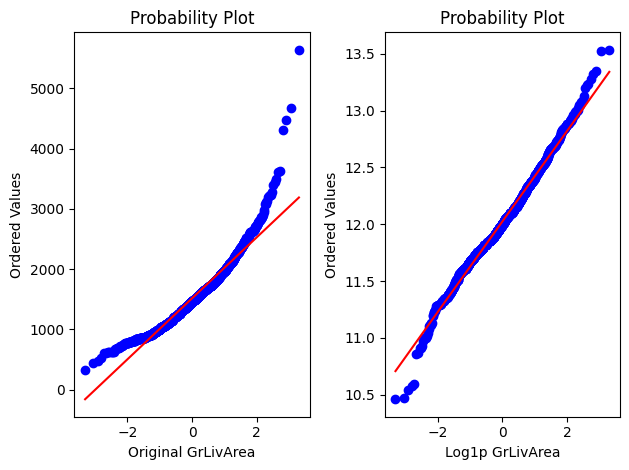

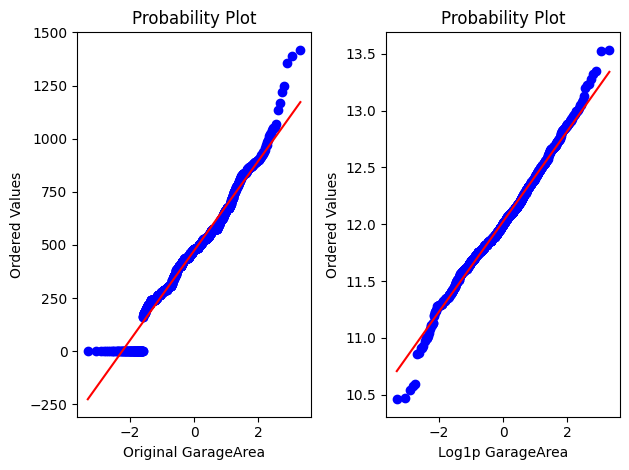

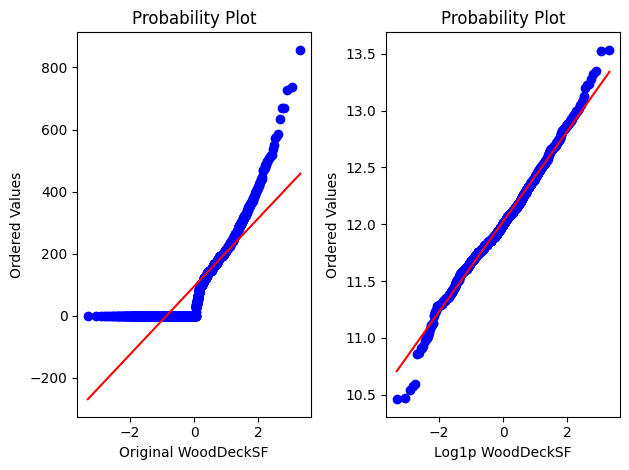

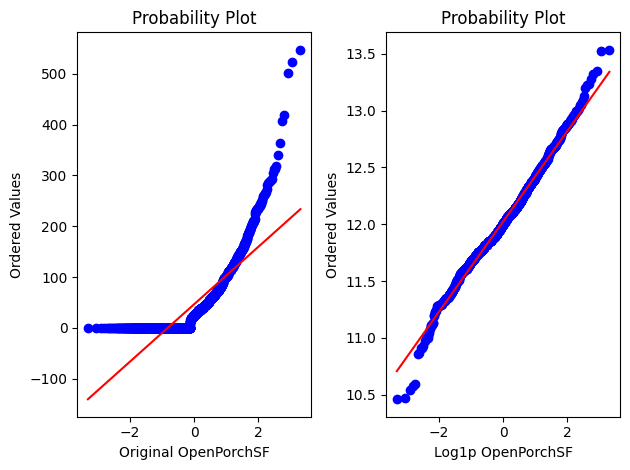

In [34]:
for var in cont_vars:

  plt.subplot(1,2,1)
  stats.probplot(
      data[var],
      dist='norm',
      plot=plt
    )
  plt.xlabel('Original ' + var)

  plt.subplot(1,2,2)
  stats.probplot(
    np.log1p(data['SalePrice'].dropna()),
    dist='norm',
    plot=plt
  )
  plt.xlabel('Log1p ' + var)

  plt.tight_layout()
  plt.show()

As you can see, the transformation was a success. Let's see relationship between transformed variables and target.

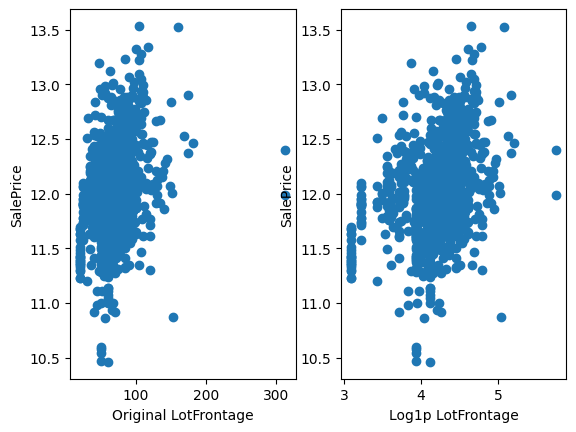

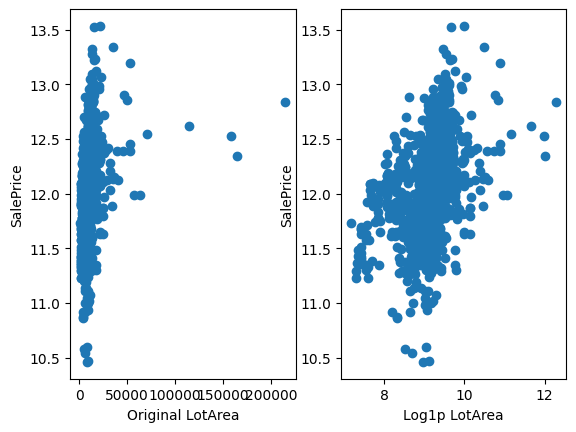

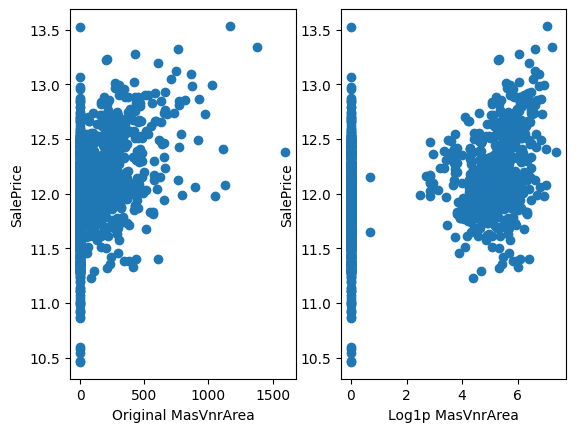

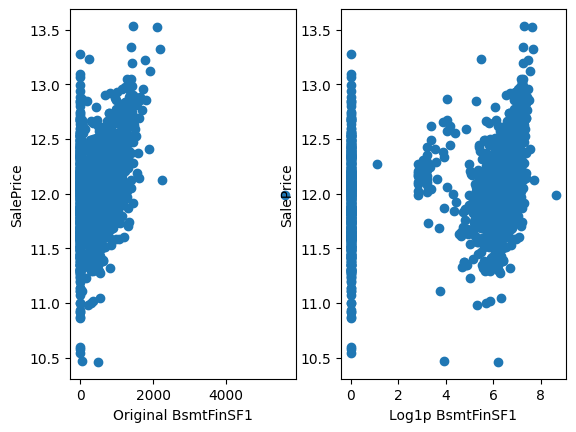

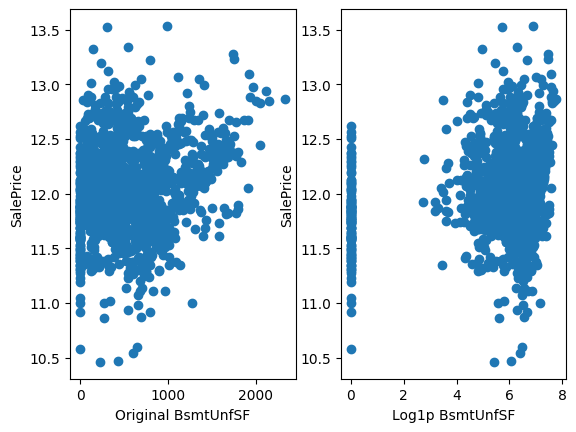

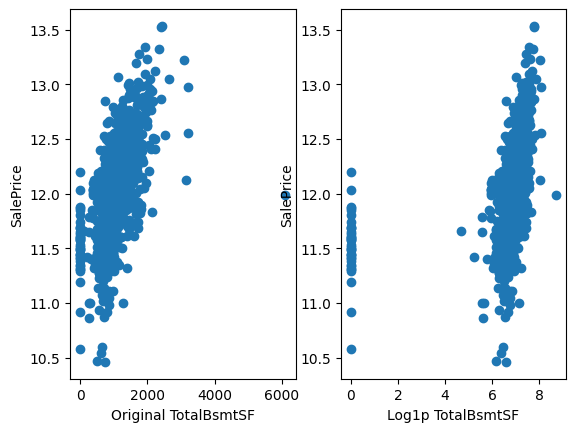

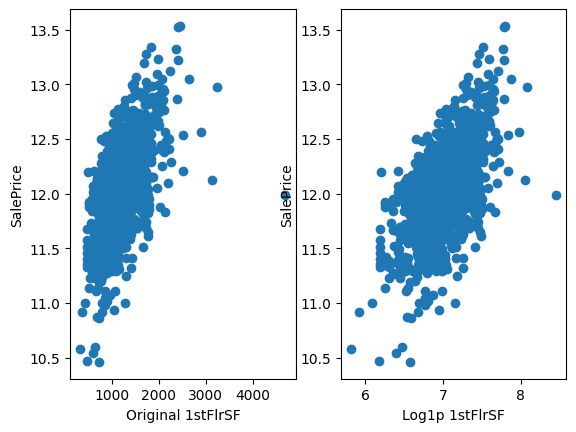

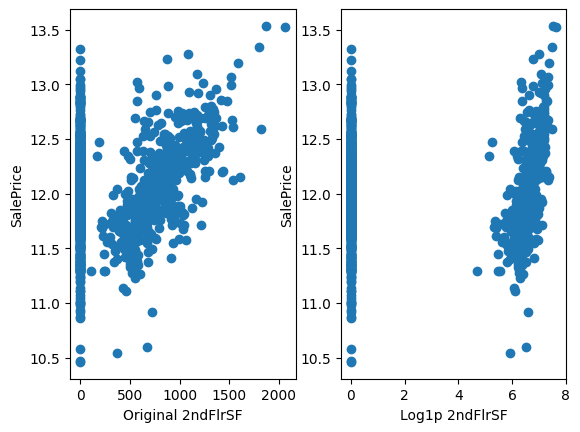

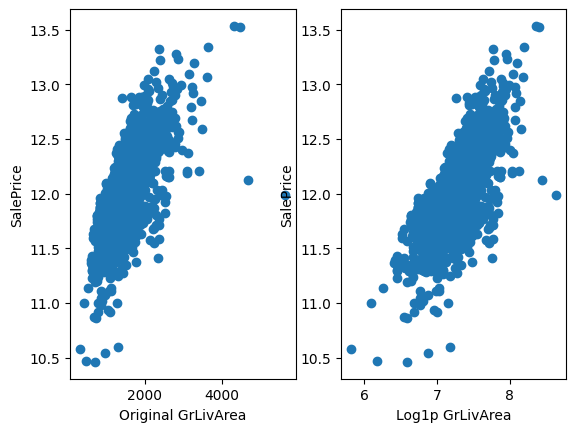

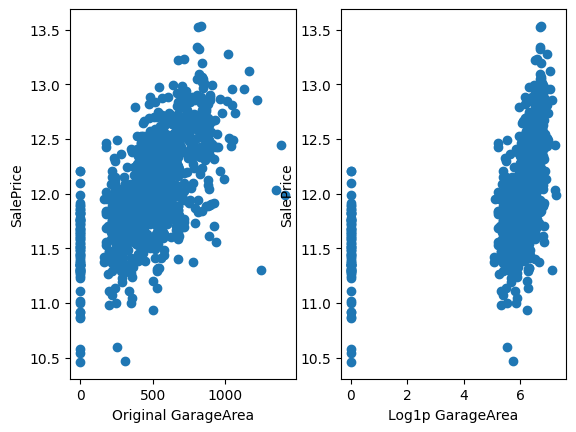

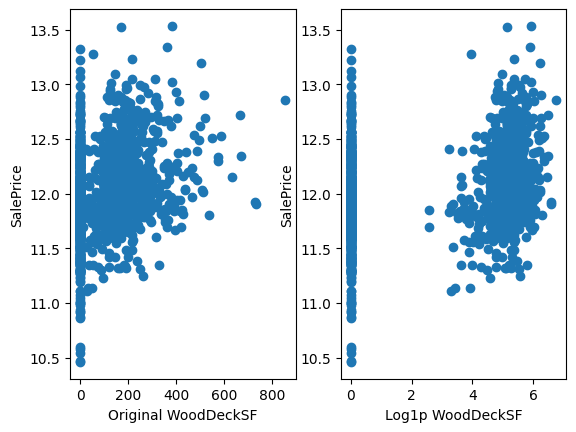

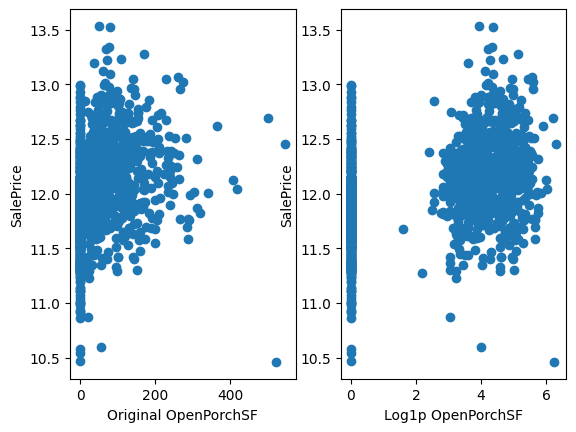

In [35]:
tmp = data.copy()
for var in cont_vars:
  tmp[var] = np.log1p(tmp[var])

for var in cont_vars:

    plt.subplot(1,2,1)
    plt.scatter(data[var], np.log(data['SalePrice']))
    plt.ylabel('SalePrice')
    plt.xlabel('Original ' + var)

    plt.subplot(1,2,2)
    plt.scatter(tmp[var], np.log(tmp['SalePrice']))
    plt.ylabel('SalePrice')
    plt.xlabel('Log1p ' + var)

    plt.show()

I will apply the transformation to only four variables, as they improve the data distribution on the histogram and, in some cases, also enhance the correlation with the target.


In [36]:
for var in ["LotArea", "LotFrontage", "1stFlrSF", "GrLivArea"]:
    X_train[var] = np.log(X_train[var])
    X_test[var] = np.log(X_test[var])

There are 4 variables that refer to the years in which the house or the garage were built or remodeled. I will capture the time elapsed between those variables and the year in which the house was sold for more information.

In [37]:
def elapsed_years(df, var):
    df[var] = df['YrSold'] - df[var]
    return df

for var in ['YearBuilt', 'YearRemodAdd', 'GarageYrBlt']:
    X_train = elapsed_years(X_train, var)
    X_test = elapsed_years(X_test, var)

X_train.drop(['YrSold'], axis=1, inplace=True)
X_test.drop(['YrSold'], axis=1, inplace=True)

# Categorical variables

In [38]:
cat_vars = [var for var in data.columns if data[var].dtypes=='O']
cat_vars

['MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition']

Some of the variables contain values ​​that have an assigned order related to quality. I will re-map strings to numbers, which determine quality.

In [39]:
qual_mappings = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5, 'Missing': 0, 'NA': 0}

qual_vars = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
             'HeatingQC', 'KitchenQual', 'FireplaceQu',
             'GarageQual', 'GarageCond',
            ]

for var in qual_vars:
    X_train[var] = X_train[var].map(qual_mappings)
    X_test[var] = X_test[var].map(qual_mappings)

In [40]:
exposure_mappings = {'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}

var = 'BsmtExposure'

X_train[var] = X_train[var].map(exposure_mappings)
X_test[var] = X_test[var].map(exposure_mappings)

In [41]:
finish_mappings = {'Missing': 0, 'NA': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}

finish_vars = ['BsmtFinType1', 'BsmtFinType2']

for var in finish_vars:
    X_train[var] = X_train[var].map(finish_mappings)
    X_test[var] = X_test[var].map(finish_mappings)

In [42]:
garage_mappings = {'Missing': 0, 'NA': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}

var = 'GarageFinish'

X_train[var] = X_train[var].map(garage_mappings)
X_test[var] = X_test[var].map(garage_mappings)

In [43]:
fence_mappings = {'Missing': 0, 'NA': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4}

var = 'Fence'

X_train[var] = X_train[var].map(fence_mappings)
X_test[var] = X_test[var].map(fence_mappings)

For the remaining categorical variables, we will group those categories that are present in less than 1% of the observations. That is, all values of categorical variables that are shared by less than 1% of houses, well be replaced by the string "Rare".

In [44]:
# capture those that I did not re-map
qual_vars  = qual_vars + finish_vars + ['BsmtExposure','GarageFinish','Fence']

# capture the remaining categorical variables
cat_others = [
    var for var in cat_vars if var not in qual_vars
] + ['MSSubClass']

len(cat_others)

30

In [45]:
def find_rare_labels(df, var, rare_perc):
  df = df.copy()

  tmp = df.groupby(var)[var].count() / len(df)

  return tmp[tmp <= rare_perc].index



for var in cat_others:
    rare_values = find_rare_labels(X_train, var, 0.01)

    X_train[var] = np.where(X_train[var].isin(
        rare_values), 'Rare', X_train[var])

    X_test[var] = np.where(X_test[var].isin(
        rare_values), 'Rare', X_test[var])

Next, I need to transform the strings of the categorical variables into numbers.
I will do it so that I capture the monotonic relationship between the label and the target.

In [46]:
def map_categories(X_train, X_test, y_train, var, target):
  tmp = pd.concat([X_train, y_train], axis=1)

  ordered_labels = tmp.groupby([var])[target].mean().sort_values().index

  ordinal_label = {k:i for i, k in enumerate(ordered_labels, 0)}

  X_train[var] = X_train[var].map(ordinal_label)
  X_test[var] = X_test[var].map(ordinal_label)

for var in cat_others:
  map_categories(X_train, X_test, y_train, var, 'SalePrice')


Let's see the results.

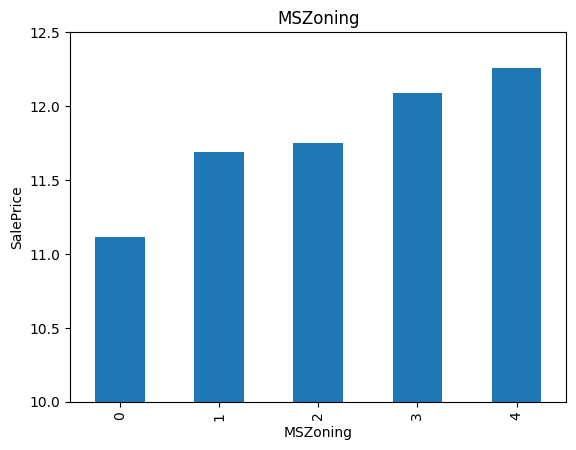

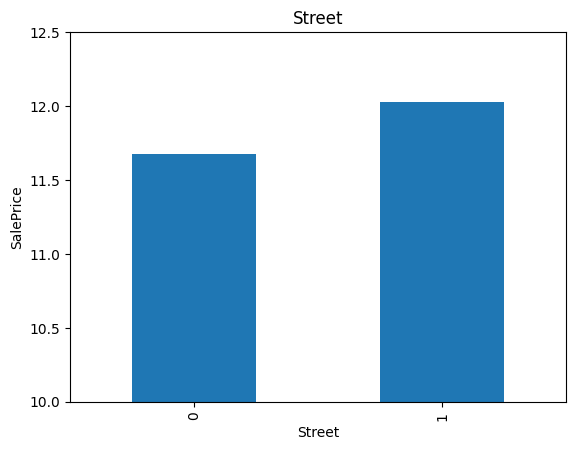

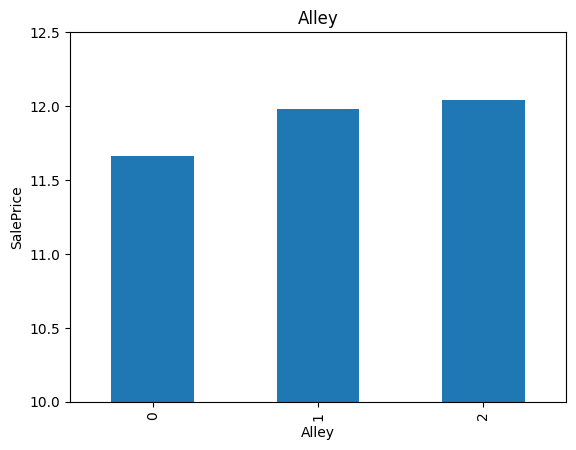

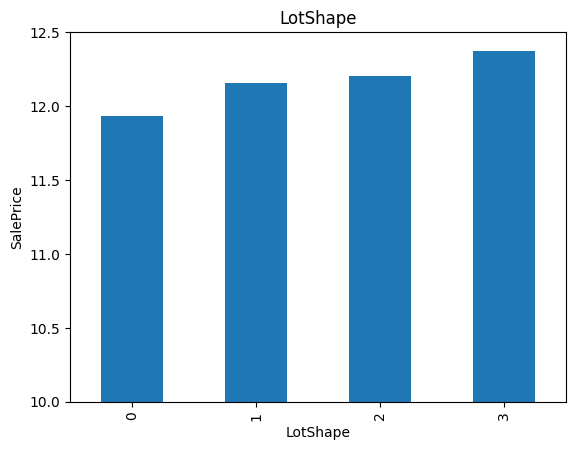

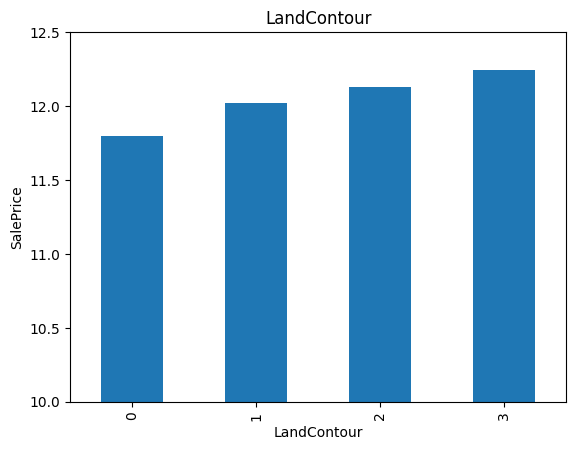

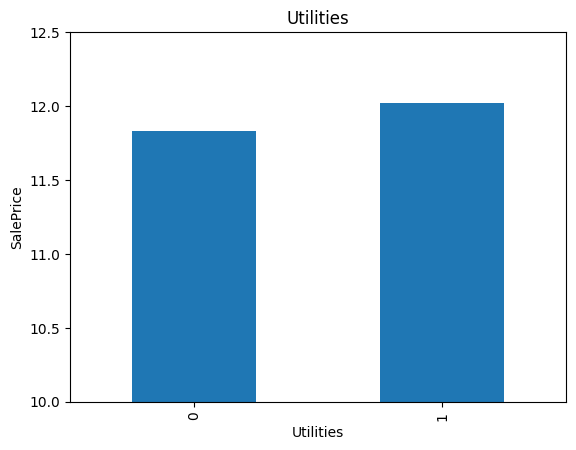

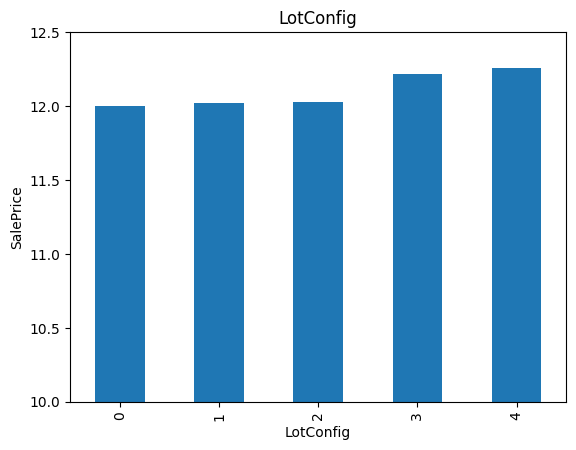

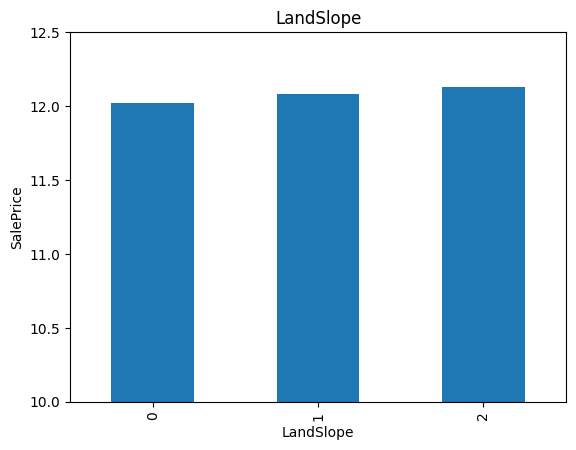

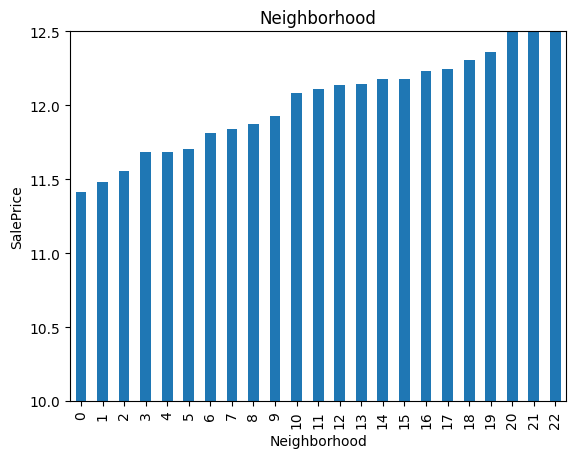

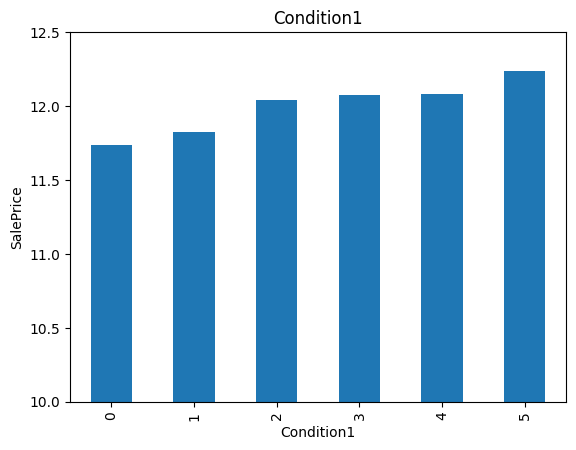

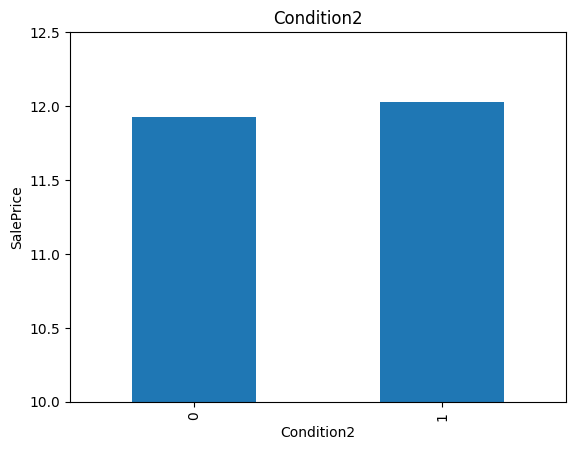

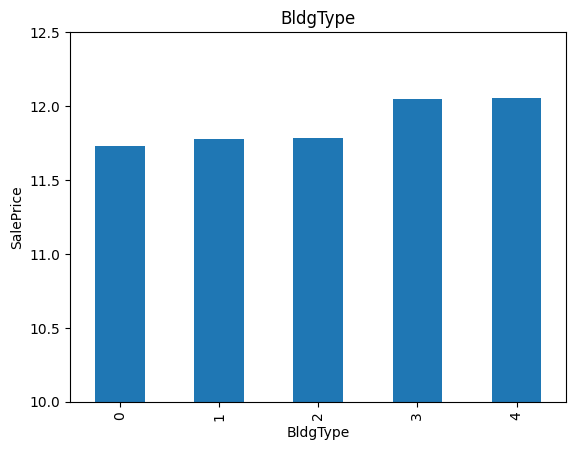

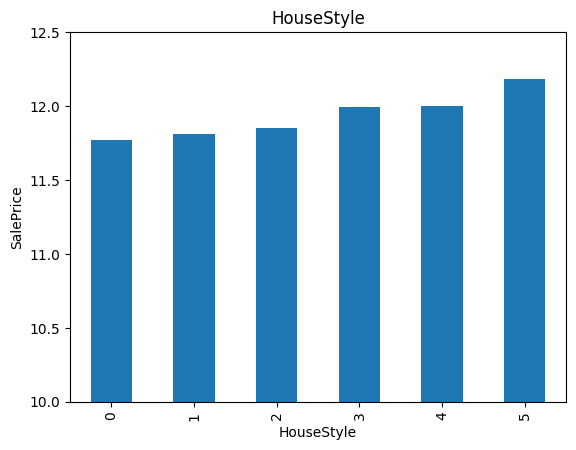

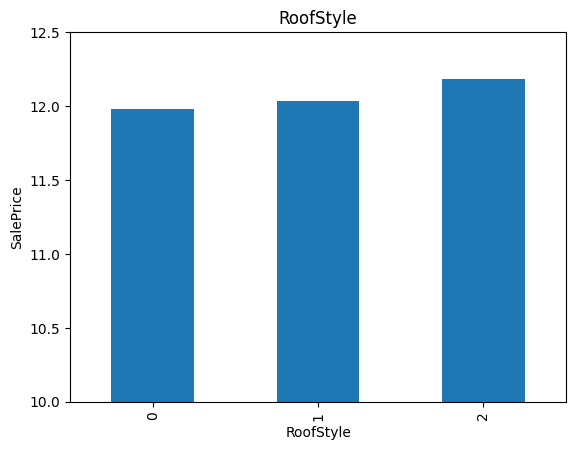

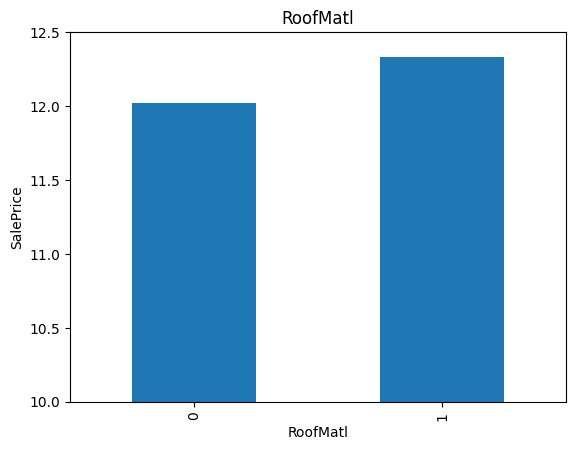

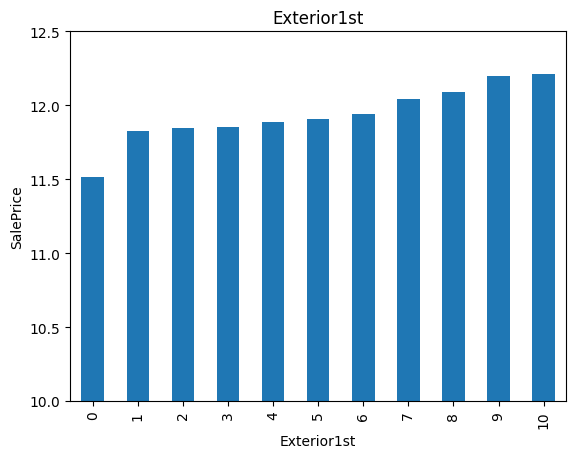

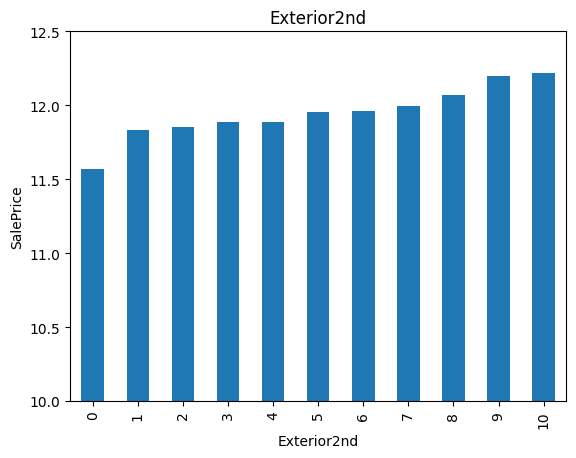

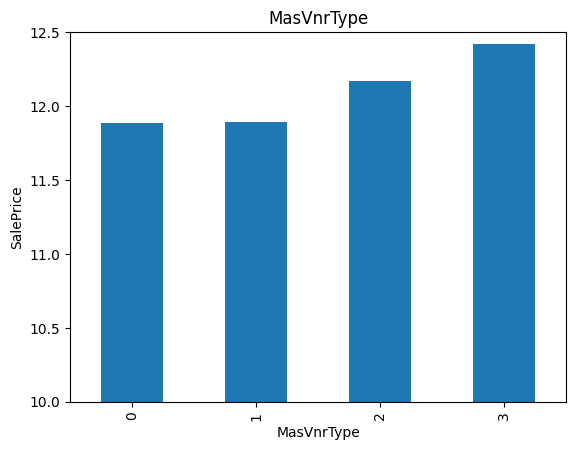

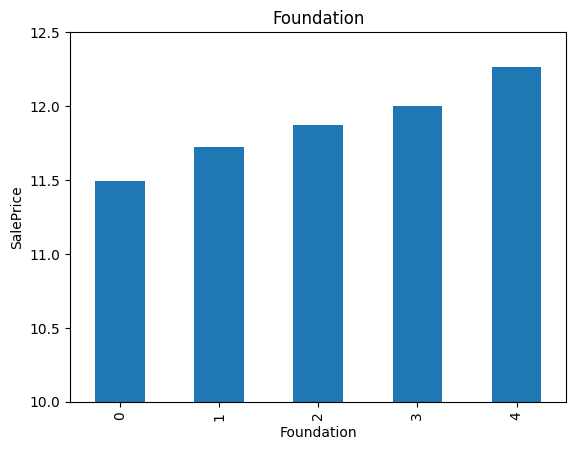

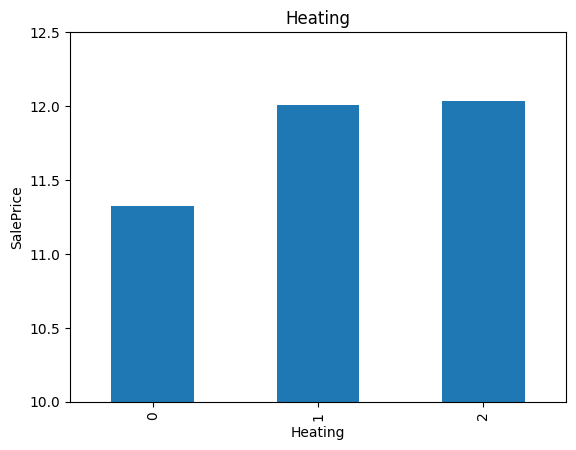

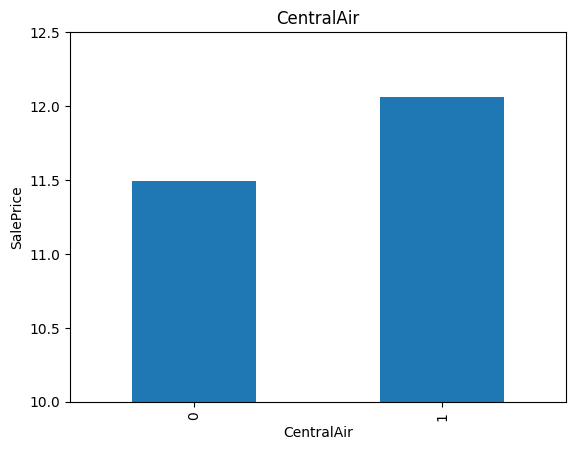

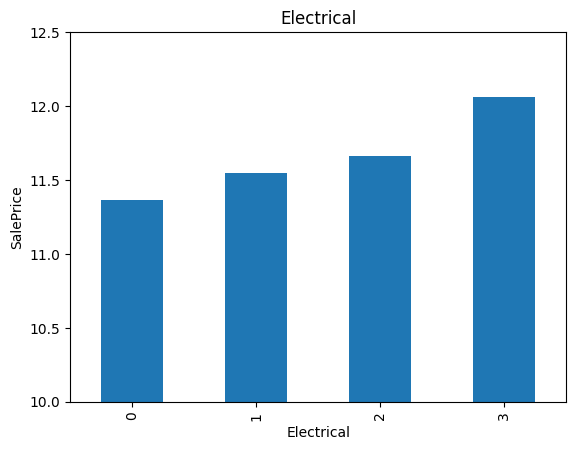

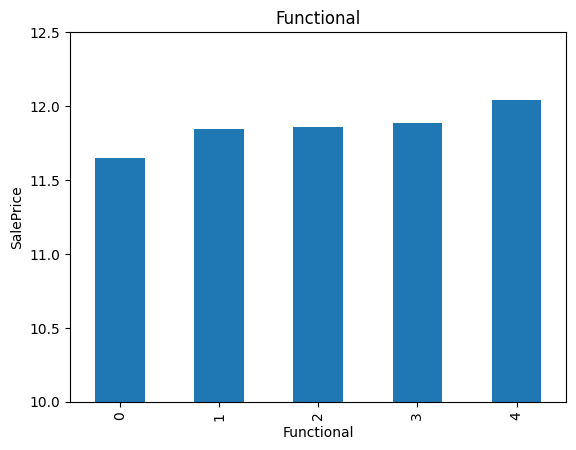

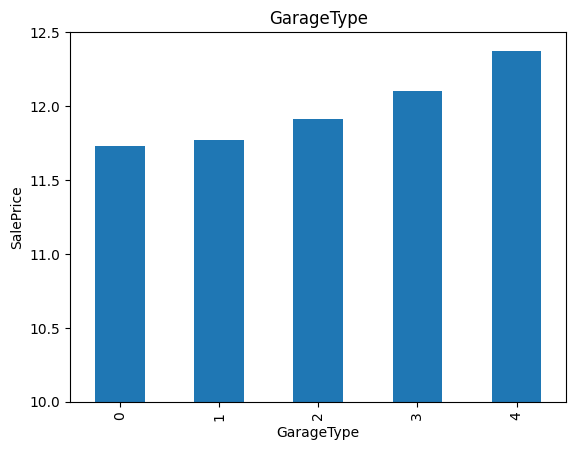

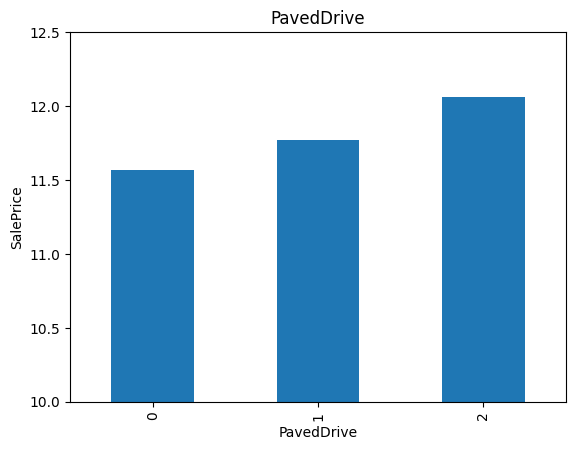

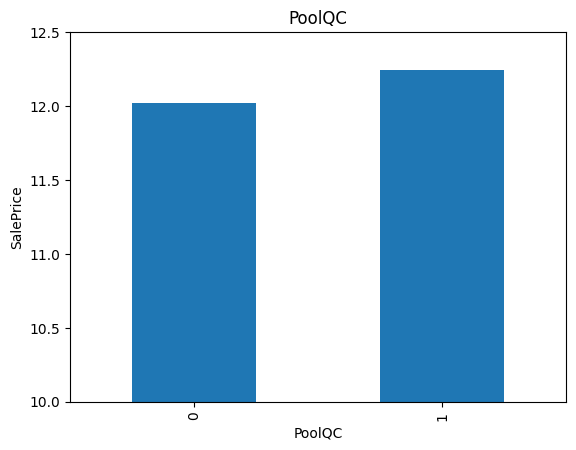

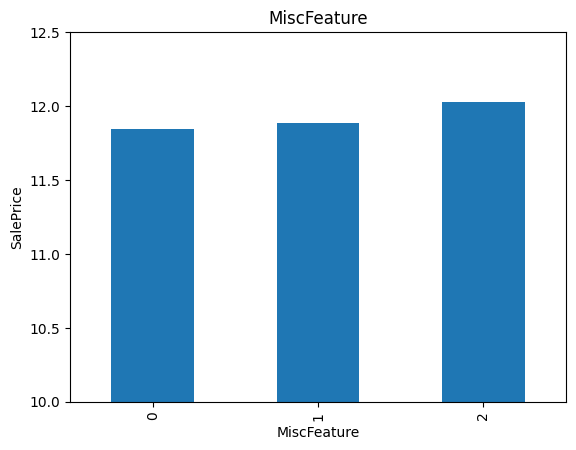

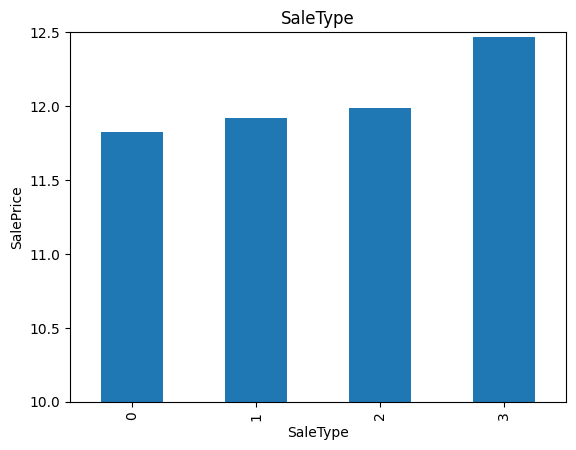

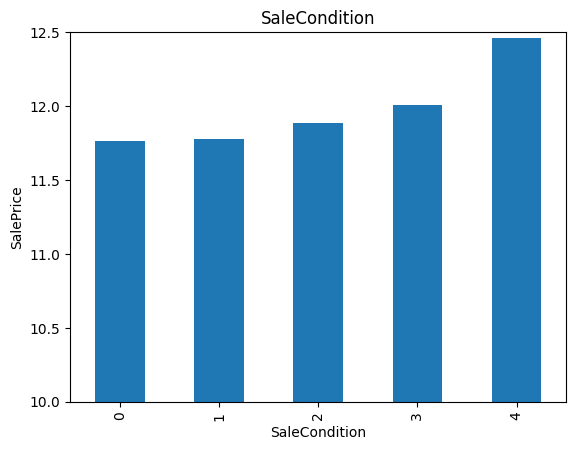

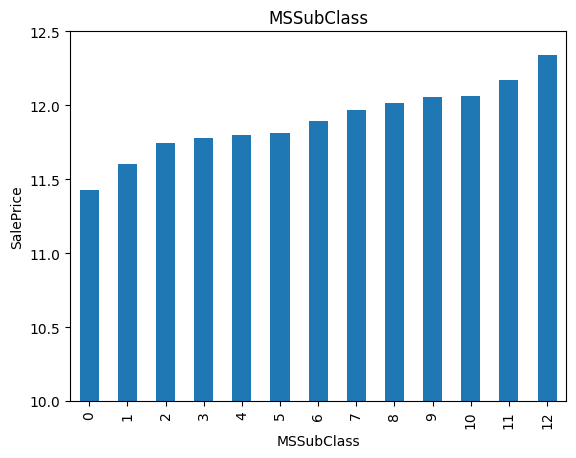

In [47]:
def analyse_vars(train, y_train, var):

    tmp = pd.concat([X_train, y_train], axis=1)

    tmp.groupby(var)['SalePrice'].mean().plot.bar()
    plt.title(var)
    plt.ylim(10, 12.5)
    plt.ylabel('SalePrice')
    plt.show()

for var in cat_others:
    analyse_vars(X_train, y_train, var)

# Feature scalling

For use in linear models, features need to be either scaled. I will scale features to the minimum and maximum values:

In [48]:
scaler = MinMaxScaler()

scaler.fit(X_train)

X_train = pd.DataFrame(
    scaler.transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_train.columns
)

X_train.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,SaleType,SaleCondition
0,0.750000,0.75,0.461171,0.377048,1.0,1.0,0.333333,1.000000,1.0,0.0,0.0,0.863636,0.4,1.0,0.75,0.6,0.777778,0.50,0.014706,0.049180,0.0,0.0,1.0,1.0,0.333333,0.00000,0.666667,0.5,1.0,0.666667,0.666667,0.666667,1.0,0.002835,0.0,0.0,0.673479,0.239935,1.0,1.00,1.0,1.0,0.559760,0.0,0.0,0.523250,0.000000,0.0,0.666667,0.0,0.375,0.333333,0.666667,0.416667,1.0,0.000000,0.0,0.75,0.018692,1.0,0.75,0.430183,0.5,0.5,1.0,0.116686,0.032907,0.0,0.0,0.0,0.0,0.0,0.00,1.0,0.0,0.545455,0.666667,0.75
1,0.750000,0.75,0.456066,0.399443,1.0,1.0,0.333333,0.333333,1.0,0.0,0.0,0.363636,0.4,1.0,0.75,0.6,0.444444,0.75,0.360294,0.049180,0.0,0.0,0.6,0.6,0.666667,0.03375,0.666667,0.5,0.5,0.333333,0.666667,0.000000,0.8,0.142807,0.0,0.0,0.114724,0.172340,1.0,1.00,1.0,1.0,0.434539,0.0,0.0,0.406196,0.333333,0.0,0.333333,0.5,0.375,0.333333,0.666667,0.250000,1.0,0.000000,0.0,0.75,0.457944,0.5,0.25,0.220028,0.5,0.5,1.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.75,1.0,0.0,0.636364,0.666667,0.75
2,0.916667,0.75,0.394699,0.347082,1.0,1.0,0.000000,0.333333,1.0,0.0,0.0,0.954545,0.4,1.0,1.00,0.6,0.888889,0.50,0.036765,0.098361,1.0,0.0,0.3,0.2,0.666667,0.25750,1.000000,0.5,1.0,1.000000,0.666667,0.000000,1.0,0.080794,0.0,0.0,0.601951,0.286743,1.0,1.00,1.0,1.0,0.627205,0.0,0.0,0.586296,0.333333,0.0,0.666667,0.0,0.250,0.333333,1.000000,0.333333,1.0,0.333333,0.8,0.75,0.046729,0.5,0.50,0.406206,0.5,0.5,1.0,0.228705,0.149909,0.0,0.0,0.0,0.0,0.0,0.00,1.0,0.0,0.090909,0.666667,0.75
3,0.750000,0.75,0.445002,0.493677,1.0,1.0,0.666667,0.666667,1.0,0.0,0.0,0.454545,0.4,1.0,0.75,0.6,0.666667,0.50,0.066176,0.163934,0.0,0.0,1.0,1.0,0.333333,0.00000,0.666667,0.5,1.0,0.666667,0.666667,1.000000,1.0,0.255670,0.0,0.0,0.018114,0.242553,1.0,1.00,1.0,1.0,0.566920,0.0,0.0,0.529943,0.333333,0.0,0.666667,0.0,0.375,0.333333,0.666667,0.250000,1.0,0.333333,0.4,0.75,0.084112,0.5,0.50,0.362482,0.5,0.5,1.0,0.469078,0.045704,0.0,0.0,0.0,0.0,0.0,0.00,1.0,0.0,0.636364,0.666667,0.75
4,0.750000,0.75,0.577658,0.402702,1.0,1.0,0.333333,0.333333,1.0,0.0,0.0,0.363636,0.4,1.0,0.75,0.6,0.555556,0.50,0.323529,0.737705,0.0,0.0,0.6,0.7,0.666667,0.17000,0.333333,0.5,0.5,0.333333,0.666667,0.000000,0.6,0.086818,0.0,0.0,0.434278,0.233224,1.0,0.75,1.0,1.0,0.549026,0.0,0.0,0.513216,0.000000,0.0,0.666667,0.0,0.375,0.333333,0.333333,0.416667,1.0,0.333333,0.8,0.75,0.411215,0.5,0.50,0.406206,0.5,0.5,1.0,0.000000,0.000000,0.0,1.0,0.0,0.0,0.0,0.00,1.0,0.0,0.545455,0.666667,0.75


In [49]:
X_train.to_csv('xtrain.csv', index=False)
X_test.to_csv('xtest.csv', index=False)

y_train.to_csv('ytrain.csv', index=False)
y_test.to_csv('ytest.csv', index=False)

# Feature selection

Because the dataset contains a large number of features, I created thematic groups. This will be helpful for the future analysis of feature utility in the models.

### Feature Selection Strategy
Feature selection was performed using a combination of statistical analysis, redundancy checks, and domain-based reasoning rather than relying on a single importance metric.

The main criteria used were:

- Near-constant features – variables dominated by a single value were considered for removal because they provide very little information for distinguishing between observations.

- Weak predictive signal – numerical features were evaluated using Pearson correlation, Spearman correlation, and Mutual Information. Features showing consistently weak relationships with the target across these measures were treated as potential removal candidates.

- Redundant information – strongly correlated predictors were examined to identify features carrying very similar information. When two variables represented essentially the same property, the more interpretable or informative feature was retained rather than keeping both.

- Domain-based redundancy – related variables were also considered within logical groups such as property size, location, and garage characteristics. Statistical results were therefore interpreted together with the meaning of each feature instead of applying correlation thresholds mechanically.

In [50]:
feature_groups = {
    'location_lot': [
        'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
        'LotShape', 'LandContour', 'LotConfig', 'LandSlope',
        'Neighborhood', 'Condition1', 'Condition2'
    ],

    'building_type': [
        'MSSubClass', 'BldgType', 'HouseStyle'
    ],

    'overall_quality': [
        'OverallQual', 'OverallCond'
    ],

    'age': [
        'YearBuilt', 'YearRemodAdd'
    ],

    'exterior': [
        'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
        'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond',
        'Foundation'
    ],

    'basement': [
        'BsmtQual', 'BsmtCond', 'BsmtExposure',
        'BsmtFinType1', 'BsmtFinSF1',
        'BsmtFinType2', 'BsmtFinSF2',
        'BsmtUnfSF', 'TotalBsmtSF',
        'BsmtFullBath', 'BsmtHalfBath'
    ],

    'utilities': [
        'Utilities', 'Heating', 'HeatingQC',
        'CentralAir', 'Electrical'
    ],

    'interior': [
        '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
        'GrLivArea', 'FullBath', 'HalfBath',
        'BedroomAbvGr', 'KitchenAbvGr',
        'KitchenQual', 'TotRmsAbvGrd', 'Functional'
    ],

    'fireplace': [
        'Fireplaces', 'FireplaceQu'
    ],

    'garage': [
        'GarageType', 'GarageYrBlt', 'GarageFinish',
        'GarageCars', 'GarageArea',
        'GarageQual', 'GarageCond', 'PavedDrive'
    ],

    'outdoor': [
        'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
        '3SsnPorch', 'ScreenPorch',
        'PoolArea', 'PoolQC', 'Fence'
    ],

    'misc': [
        'MiscFeature', 'MiscVal'
    ],

    'sale': [
        'MoSold', 'SaleType', 'SaleCondition'
    ]
}

In [51]:
from numpy.random.mtrand import f
def create_feature_report(X, y, feature_groups):

  feature_to_group = {
      feature: group
      for group, features in feature_groups.items()
      for feature in features
  }

  report = pd.DataFrame(index=X.columns)

  report['group'] = [
      feature_to_group.get(feature, 'Other')
      for feature in X.columns
  ]

  report['n_unique'] = X.nunique()

  report['dominant_share'] = [
      X[feature].value_counts(normalize=True).iloc[0]
      for feature in X.columns
  ]

  report['Variance'] = X.var()

  report['Pearson'] = X.corrwith(y).abs()

  report['Spearman'] = X.apply(
      lambda x: x.corr(y, method='spearman')
  ).abs()

  from sklearn.feature_selection import mutual_info_regression

  mi = mutual_info_regression(
      X,
      y,
      random_state=424242819
  )
  report['mutual_information'] = pd.Series(
      mi,
      index=X.columns
  )

  corr = X.corr().abs()
  np.fill_diagonal(corr.values, np.nan)

  report['max_abs_corr'] = corr.max()

  report['most_correlated_with'] = corr.idxmax()

  return report.reset_index(names='feature')



In [52]:
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

feature_report = create_feature_report(
    X_train,
    y_train,
    feature_groups
)

In [53]:
feature_report['strong_signal_count'] = (
    (feature_report['Pearson'] >= 0.5).astype(int)
    + (feature_report['Spearman'] >= 0.5).astype(int)
    + (feature_report['mutual_information'] >= 0.2).astype(int)
)

In [54]:
feature_report['weak_signal'] = (
    (feature_report['Pearson'] < 0.10)
    & (feature_report['Spearman'] < 0.10)
    & (feature_report['mutual_information'] < 0.02)
)

In [55]:
feature_report['near_constant'] = (
    feature_report['dominant_share'] >= 0.98
)

feature_report['near_constant_soft'] = (
    feature_report['dominant_share'] >= 0.95
)

In [56]:
feature_report['high_redundancy'] = (
    feature_report['max_abs_corr'] >= 0.85
)

In [57]:
feature_report.sort_values(
    'dominant_share',
    ascending=False
).head(5)

,feature,group,n_unique,dominant_share,Variance,Pearson,Spearman,mutual_information,max_abs_corr,most_correlated_with,strong_signal_count,weak_signal,near_constant,near_constant_soft,high_redundancy
8,Utilities,utilities,2,0.999239,0.000761,0.013215,0.017716,0.009382,0.119095,SaleType,0,True,True,True,False
4,Street,location_lot,2,0.996195,0.003794,0.052953,0.036954,0.000000,0.181530,MiscVal,0,True,True,True,False
70,PoolArea,outdoor,7,0.995434,0.002865,0.038471,0.046682,0.000657,0.988232,PoolQC,0,True,True,True,True
71,PoolQC,outdoor,2,0.995434,0.004549,0.036888,0.046647,0.000283,0.988232,PoolArea,0,True,True,True,True
13,Condition2,location_lot,2,0.991629,0.008308,0.022712,0.024190,0.000000,0.109412,YearBuilt,0,True,True,True,False


In [58]:
drop_candidate = feature_report[(
    feature_report['weak_signal']
    & (
        feature_report['near_constant']
        | feature_report['high_redundancy']
    )
)]['feature'].tolist()

core_features = feature_report[
    feature_report['strong_signal_count'] >= 2
]['feature'].tolist()

In [59]:
print('All features:', len(feature_report))
print('Core features:', len(core_features))
print('Drop candidates:', len(drop_candidate))
print(
    'Remaining:',
    len(feature_report) - len(core_features) - len(drop_candidate)
)

All features: 78
Core features: 19
Drop candidates: 11
Remaining: 48


In [60]:
remaining_features = [
    feature
    for feature in feature_report['feature']
    if feature not in core_features
    and feature not in drop_candidate
]

Next, I will analyze remaining_features to determine which feature to assign to the appropriate group.

In [61]:
from IPython.display import display

def analyze_feature_group(
    group_name,
    feature_groups,
    feature_report,
    X_train,
    core_features,
    remaining_features,
    drop_candidate
):

    # ------------------------------------------------
    # 1. Features belonging to selected group
    # ------------------------------------------------

    group_features = feature_groups[group_name]


    # ------------------------------------------------
    # 2. General report for the whole group
    # ------------------------------------------------

    group_report = feature_report[
        feature_report['feature'].isin(group_features)
    ].copy()

    group_report['is_core'] = (
        group_report['feature'].isin(core_features)
    )

    group_report['is_drop_candidate'] = (
        group_report['feature'].isin(drop_candidate)
    )

    group_report = group_report[
        [
            'feature',
            'Pearson',
            'Spearman',
            'mutual_information',
            'dominant_share',
            'max_abs_corr',
            'most_correlated_with',
            'is_core',
            'is_drop_candidate'
        ]
    ]

    group_report = group_report.sort_values(
        'mutual_information',
        ascending=False
    )

    print(f'===== {group_name.upper()} - GENERAL REPORT =====')

    display(group_report)


    # ------------------------------------------------
    # 3. Correlation matrix for the whole group
    # ------------------------------------------------

    group_corr = X_train[group_features].corr()

    plt.figure(
        figsize=(
            max(7, len(group_features)),
            max(5, len(group_features) * 0.8)
        )
    )

    sns.heatmap(
        group_corr,
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        vmin=-1,
        vmax=1
    )

    plt.title(
        f'Correlation matrix - {group_name.upper()}'
    )

    plt.tight_layout()
    plt.show()


    # ------------------------------------------------
    # 4. Core / remaining features
    # ------------------------------------------------

    group_core = [
        feature
        for feature in group_features
        if feature in core_features
    ]

    group_remaining = [
        feature
        for feature in group_features
        if feature in remaining_features
    ]

    print('CORE:')
    print(group_core)

    print('\nREMAINING:')
    print(group_remaining)


    # ------------------------------------------------
    # 5. Correlation: remaining vs core
    # ------------------------------------------------

    if group_core and group_remaining:

        core_remaining_corr = (
            X_train[group_core + group_remaining]
            .corr()
            .loc[group_remaining, group_core]
            .abs()
        )

        print(
            f'\n===== {group_name.upper()} '
            '- REMAINING VS CORE ====='
        )

        display(core_remaining_corr)

        plt.figure(
            figsize=(
                max(7, len(group_core) * 1.5),
                max(3, len(group_remaining))
            )
        )

        sns.heatmap(
            core_remaining_corr,
            annot=True,
            fmt='.2f',
            cmap='Reds',
            vmin=0,
            vmax=1
        )

        plt.title(
            f'{group_name.upper()}: remaining vs core'
        )

        plt.tight_layout()
        plt.show()

    else:
        core_remaining_corr = None

        print(
            '\nRemaining vs core correlation matrix '
            'cannot be created.'
        )

        if not group_core:
            print('No CORE features in this group.')

        if not group_remaining:
            print('No REMAINING features in this group.')


    # ------------------------------------------------
    # 6. Report only for remaining features
    # ------------------------------------------------

    group_remaining_report = group_report[
        group_report['feature'].isin(group_remaining)
    ].copy()

    group_remaining_report = (
        group_remaining_report
        .sort_values(
            'mutual_information',
            ascending=False
        )
    )

    group_remaining_report = group_remaining_report[
        [
            'feature',
            'Pearson',
            'Spearman',
            'mutual_information',
            'dominant_share',
            'max_abs_corr',
            'most_correlated_with'
        ]
    ]

    print(
        f'\n===== {group_name.upper()} '
        '- REMAINING FEATURES ====='
    )

    display(group_remaining_report)


    # ------------------------------------------------
    # 7. Return results for further use
    # ------------------------------------------------

    return {
        'features': group_features,
        'core': group_core,
        'remaining': group_remaining,
        'report': group_report,
        'remaining_report': group_remaining_report,
        'correlation_matrix': group_corr,
        'core_remaining_corr': core_remaining_corr
    }

===== LOCATION_LOT - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
11,Neighborhood,0.742885,0.760102,0.515837,0.152968,0.676913,OverallQual,True,False
3,LotArea,0.402494,0.460405,0.205992,0.017504,0.652400,LotFrontage,False,False
2,LotFrontage,0.333026,0.372700,0.203325,0.177321,0.652400,LotArea,False,False
1,MSZoning,0.416743,0.427986,0.117216,0.788432,0.515240,Neighborhood,False,False
6,LotShape,0.291714,0.325342,0.084199,0.630898,0.367711,LotArea,False,False
5,Alley,0.162679,0.136820,0.024896,0.938356,0.307679,YearBuilt,False,False
7,LandContour,0.149479,0.152689,0.020573,0.898782,0.333032,LandSlope,False,False
12,Condition1,0.160683,0.180083,0.012279,0.865297,0.187960,YearBuilt,False,False
9,LotConfig,0.137222,0.109906,0.007487,0.729072,0.355224,LotShape,False,False
10,LandSlope,0.041956,0.056047,0.001430,0.942922,0.333032,LandContour,False,False


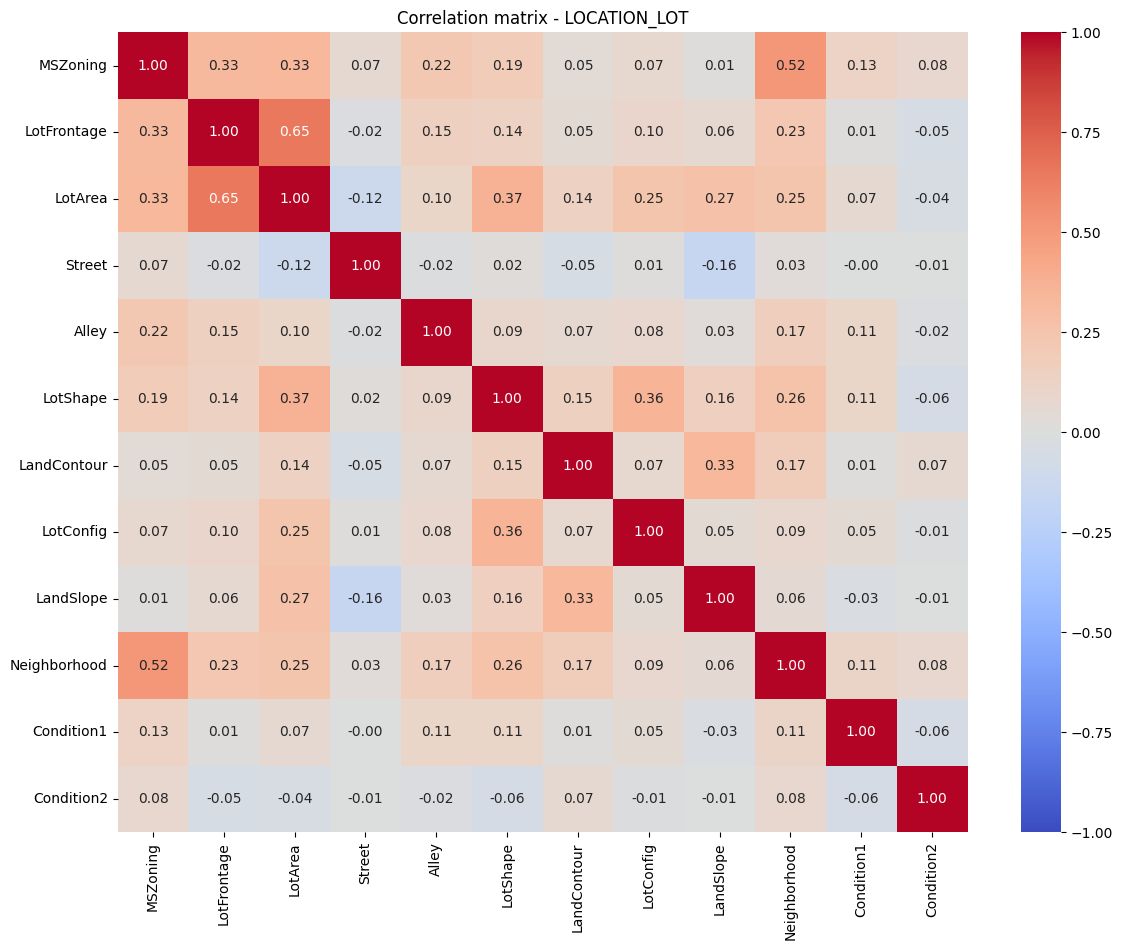

CORE:
['Neighborhood']

REMAINING:
['MSZoning', 'LotFrontage', 'LotArea', 'Alley', 'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Condition1']

===== LOCATION_LOT - REMAINING VS CORE =====


,Neighborhood
MSZoning,0.515240
LotFrontage,0.229293
LotArea,0.247929
Alley,0.166844
LotShape,0.259389
LandContour,0.174987
LotConfig,0.085644
LandSlope,0.059445
Condition1,0.111068


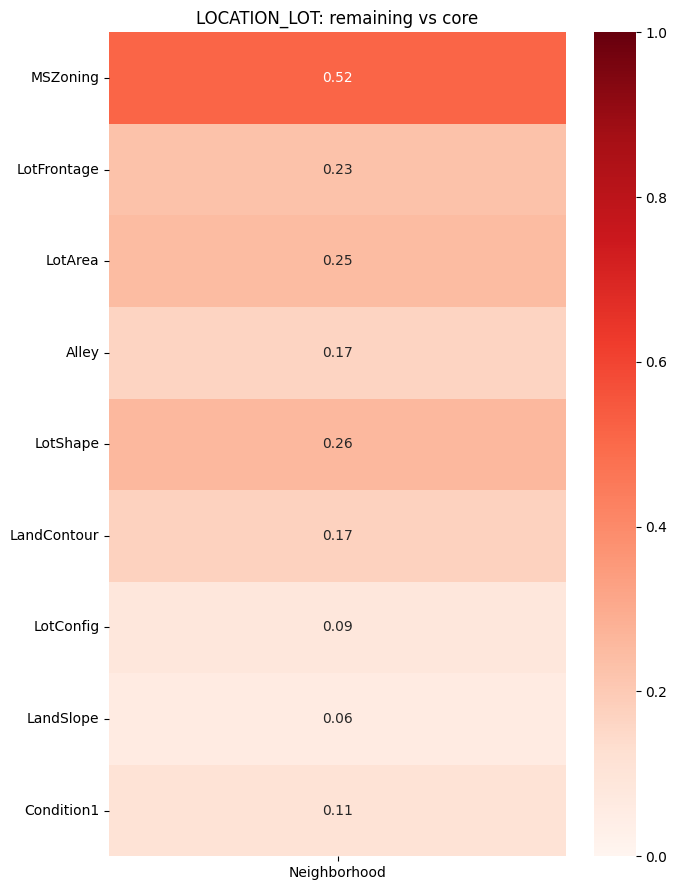


===== LOCATION_LOT - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
3,LotArea,0.402494,0.460405,0.205992,0.017504,0.652400,LotFrontage
2,LotFrontage,0.333026,0.372700,0.203325,0.177321,0.652400,LotArea
1,MSZoning,0.416743,0.427986,0.117216,0.788432,0.515240,Neighborhood
6,LotShape,0.291714,0.325342,0.084199,0.630898,0.367711,LotArea
5,Alley,0.162679,0.136820,0.024896,0.938356,0.307679,YearBuilt
7,LandContour,0.149479,0.152689,0.020573,0.898782,0.333032,LandSlope
12,Condition1,0.160683,0.180083,0.012279,0.865297,0.187960,YearBuilt
9,LotConfig,0.137222,0.109906,0.007487,0.729072,0.355224,LotShape
10,LandSlope,0.041956,0.056047,0.001430,0.942922,0.333032,LandContour


In [62]:
# ============================================================
# LOCATION / LOT
# ============================================================

location_analysis = analyze_feature_group(
    group_name='location_lot',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [63]:
location_lot_keep = [
    'Neighborhood',
    'LotArea',
    'LotFrontage',
    'MSZoning',
    'LotShape'
]

location_drop = [
    'Alley',
    'LandContour',
    'Condition1',
    'LotConfig',
    'LandSlope'
]

===== BUILDING_TYPE - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
0,MSSubClass,0.561834,0.581834,0.284381,0.363775,0.594757,YearBuilt,True,False
15,HouseStyle,0.299646,0.334001,0.081319,0.496195,0.504498,2ndFlrSF,False,False
14,BldgType,0.170050,0.167532,0.043170,0.836377,0.636570,KitchenAbvGr,False,False


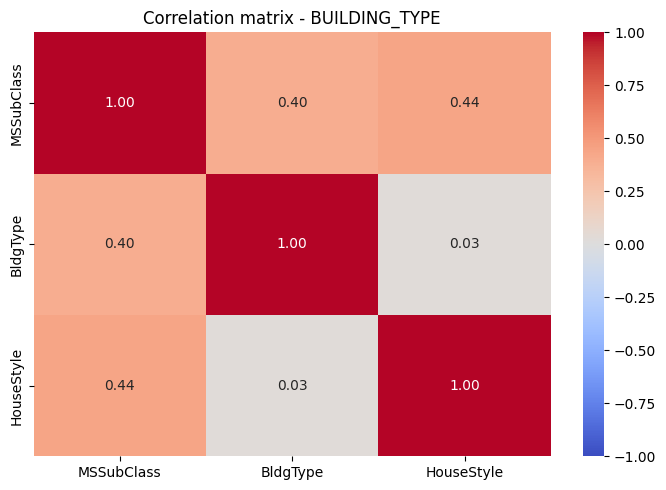

CORE:
['MSSubClass']

REMAINING:
['BldgType', 'HouseStyle']

===== BUILDING_TYPE - REMAINING VS CORE =====


,MSSubClass
BldgType,0.395982
HouseStyle,0.437714


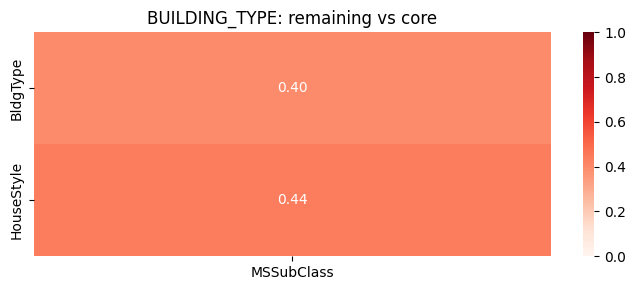


===== BUILDING_TYPE - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
15,HouseStyle,0.299646,0.334001,0.081319,0.496195,0.504498,2ndFlrSF
14,BldgType,0.170050,0.167532,0.043170,0.836377,0.636570,KitchenAbvGr


In [64]:
# ============================================================
# BUILDING TYPE
# ============================================================

building_type_analysis = analyze_feature_group(
    group_name='building_type',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [65]:
building_type_keep = [
    'MSSubClass',
    'HouseStyle'
]

building_type_drop = [
    'BldgType'
]

===== OVERALL_QUALITY - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
16,OverallQual,0.813593,0.806229,0.565350,0.270167,0.723540,ExterQual,True,False
17,OverallCond,0.025686,0.122317,0.115999,0.557078,0.383705,ExterCond,False,False


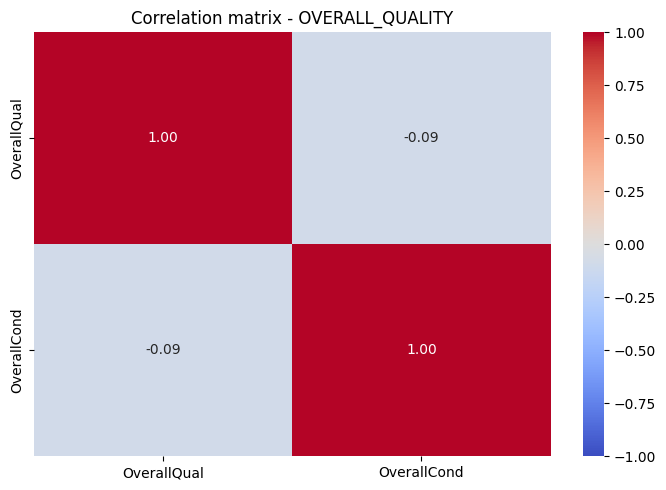

CORE:
['OverallQual']

REMAINING:
['OverallCond']

===== OVERALL_QUALITY - REMAINING VS CORE =====


,OverallQual
OverallCond,0.091855


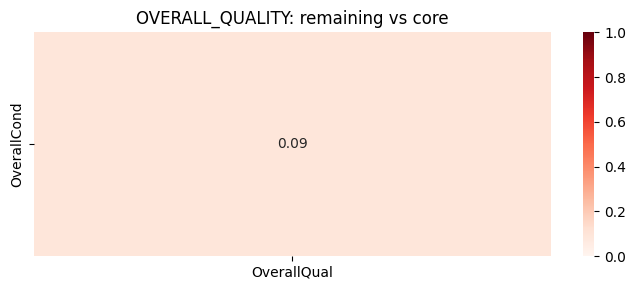


===== OVERALL_QUALITY - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
17,OverallCond,0.025686,0.122317,0.115999,0.557078,0.383705,ExterCond


In [66]:
# ============================================================
# OVERALL QUALITY
# ============================================================

overall_quality_analysis = analyze_feature_group(
    group_name='overall_quality',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [67]:
overall_quality_to_keep = [
    'OverallQual'
]

overall_quality_to_drop = [
    'OverallCond'
]

===== AGE - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
18,YearBuilt,0.585320,0.647061,0.344948,0.063166,0.781937,GarageYrBlt,True,False
19,YearRemodAdd,0.576395,0.583288,0.258398,0.085236,0.627969,KitchenQual,True,False


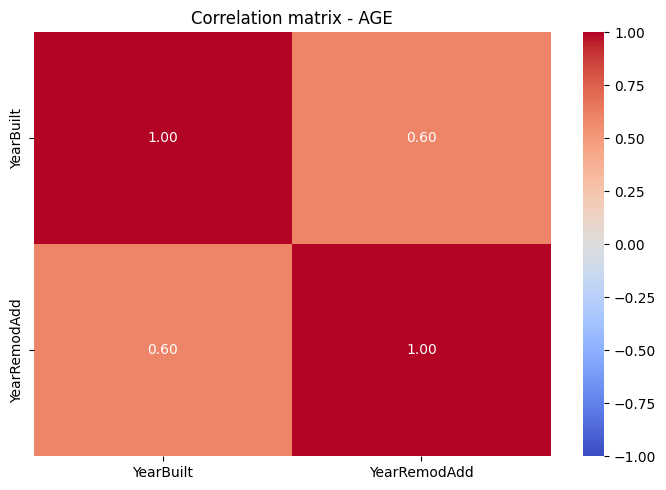

CORE:
['YearBuilt', 'YearRemodAdd']

REMAINING:
[]

Remaining vs core correlation matrix cannot be created.
No REMAINING features in this group.

===== AGE - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with


In [68]:
# ============================================================
# AGE / REMODELING
# ============================================================

age_analysis = analyze_feature_group(
    group_name='age',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

===== EXTERIOR - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
26,ExterQual,0.678667,0.682736,0.337356,0.619482,0.723540,OverallQual,True,False
28,Foundation,0.550732,0.574327,0.213652,0.437595,0.711876,YearBuilt,True,False
23,Exterior2nd,0.398806,0.434062,0.167695,0.343988,0.919617,Exterior1st,False,False
22,Exterior1st,0.413760,0.447794,0.153374,0.352359,0.919617,Exterior2nd,False,False
24,MasVnrType,0.431602,0.425054,0.098480,0.601218,0.575271,MasVnrArea,False,False
25,MasVnrArea,0.425796,0.424183,0.096940,0.594368,0.575271,MasVnrType,False,False
27,ExterCond,0.060016,0.019289,0.015258,0.878234,0.383705,OverallCond,False,False
20,RoofStyle,0.199880,0.157517,0.014601,0.777017,0.304284,1stFlrSF,False,False
21,RoofMatl,0.105779,0.097493,0.002122,0.980974,0.239380,LandSlope,False,False


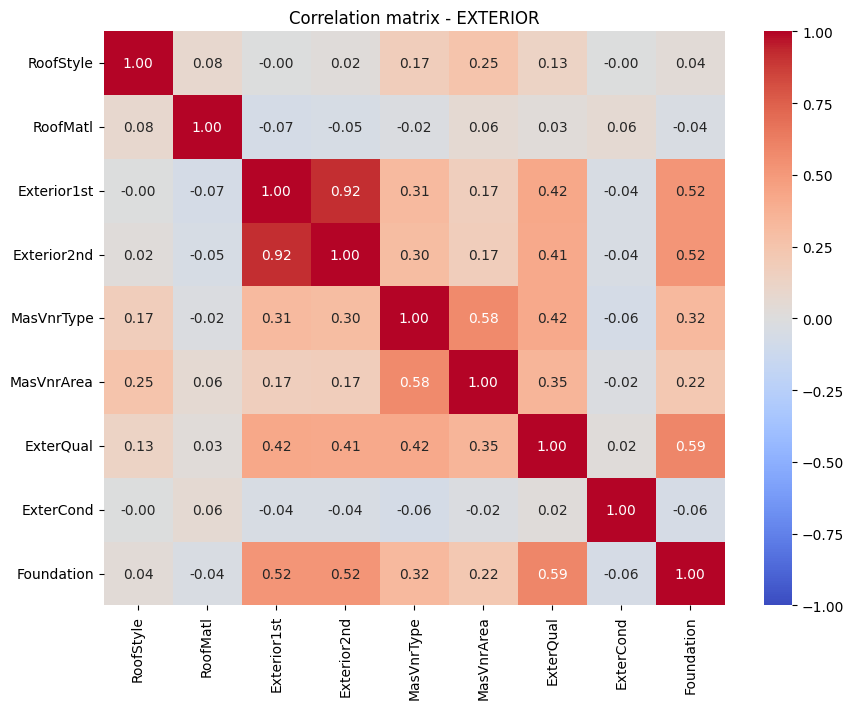

CORE:
['ExterQual', 'Foundation']

REMAINING:
['RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterCond']

===== EXTERIOR - REMAINING VS CORE =====


,ExterQual,Foundation
RoofStyle,0.126190,0.037555
RoofMatl,0.029913,0.036302
Exterior1st,0.421998,0.518435
Exterior2nd,0.414862,0.523309
MasVnrType,0.417959,0.320553
MasVnrArea,0.345016,0.223814
ExterCond,0.015695,0.061767


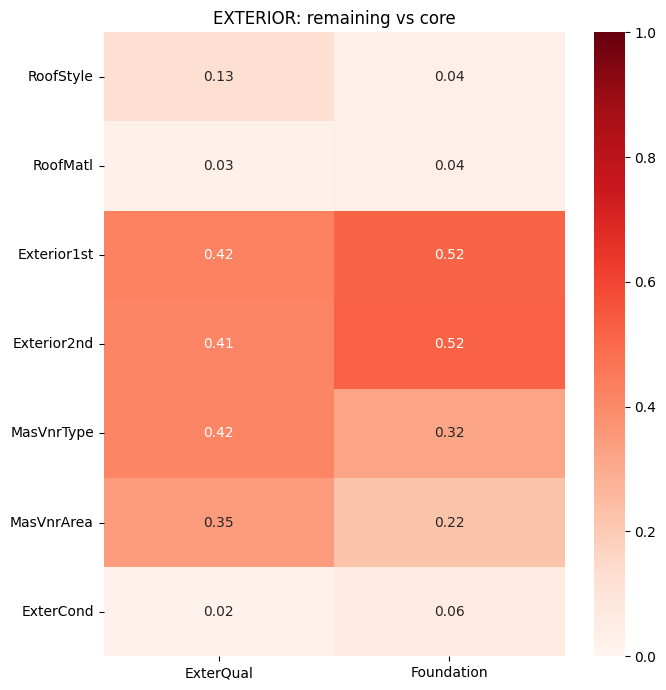


===== EXTERIOR - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
23,Exterior2nd,0.398806,0.434062,0.167695,0.343988,0.919617,Exterior1st
22,Exterior1st,0.413760,0.447794,0.153374,0.352359,0.919617,Exterior2nd
24,MasVnrType,0.431602,0.425054,0.098480,0.601218,0.575271,MasVnrArea
25,MasVnrArea,0.425796,0.424183,0.096940,0.594368,0.575271,MasVnrType
27,ExterCond,0.060016,0.019289,0.015258,0.878234,0.383705,OverallCond
20,RoofStyle,0.199880,0.157517,0.014601,0.777017,0.304284,1stFlrSF
21,RoofMatl,0.105779,0.097493,0.002122,0.980974,0.239380,LandSlope


In [69]:
# ============================================================
# EXTERIOR / STRUCTURE
# ============================================================

exterior_analysis = analyze_feature_group(
    group_name='exterior',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [70]:
exterior_keep = [
    'ExterQual',
    'Foundation',
    'Exterior1st',
    'MasVnrType',
    'MasVnrArea'
]

exterior_drop = [
    'Exterior2nd',
    'ExterCond',
    'RoofStyle',
    'RoofMatl'
]

===== BASEMENT - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
37,TotalBsmtSF,0.610014,0.609117,0.382571,0.024353,0.774033,1stFlrSF,True,False
29,BsmtQual,0.656517,0.671279,0.328063,0.472603,0.725646,YearBuilt,True,False
33,BsmtFinSF1,0.375752,0.310490,0.166833,0.323440,0.695898,BsmtFinType1,False,False
32,BsmtFinType1,0.332294,0.356270,0.152053,0.323440,0.695898,BsmtFinSF1,False,False
36,BsmtUnfSF,0.209785,0.172766,0.123753,0.079148,0.496833,BsmtFinSF1,False,False
31,BsmtExposure,0.339268,0.317137,0.058802,0.679604,0.362122,BsmtFinSF1,False,False
46,BsmtFullBath,0.249521,0.241236,0.027136,0.590563,0.653736,BsmtFinSF1,False,False
30,BsmtCond,0.209834,0.199141,0.020888,0.920091,0.232881,YearBuilt,False,False
34,BsmtFinType2,0.001832,0.027803,0.010565,0.885845,0.870824,BsmtFinSF2,False,True
47,BsmtHalfBath,0.004404,0.012977,0.001657,0.944444,0.145243,BsmtFullBath,False,False


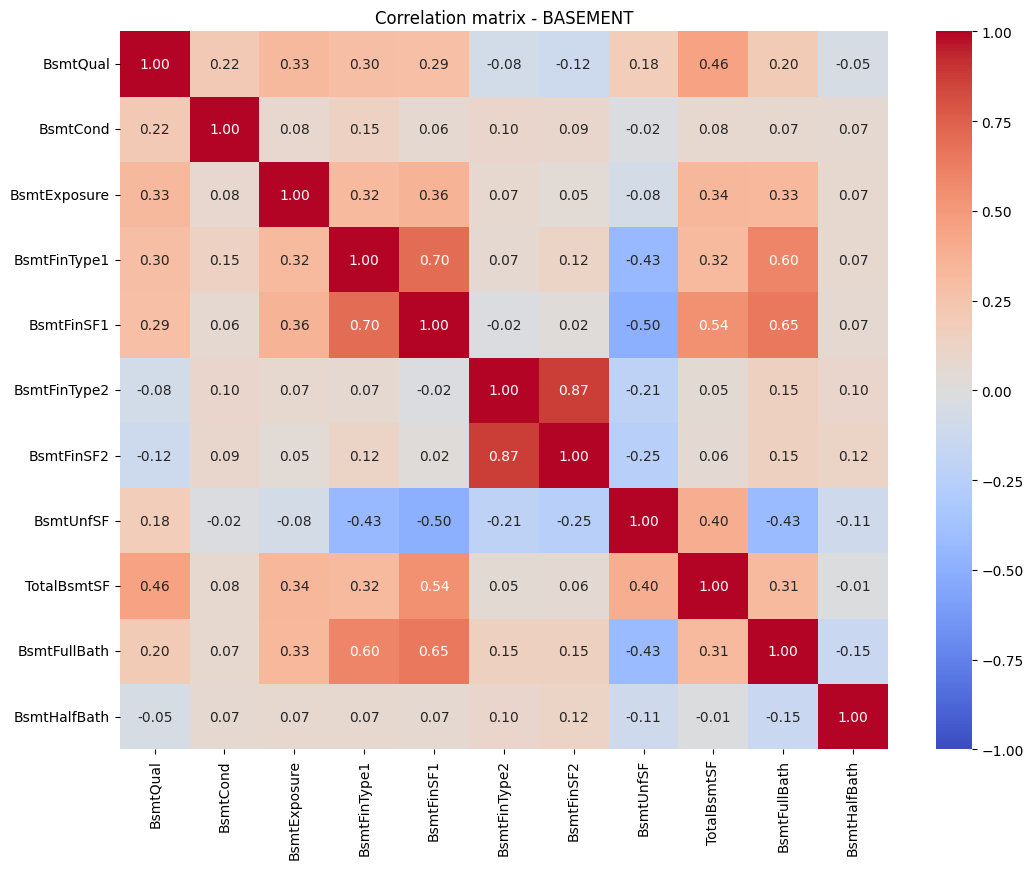

CORE:
['BsmtQual', 'TotalBsmtSF']

REMAINING:
['BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtUnfSF', 'BsmtFullBath', 'BsmtHalfBath']

===== BASEMENT - REMAINING VS CORE =====


,BsmtQual,TotalBsmtSF
BsmtCond,0.215071,0.075672
BsmtExposure,0.325679,0.337347
BsmtFinType1,0.295359,0.315761
BsmtFinSF1,0.288798,0.539485
BsmtUnfSF,0.183119,0.398219
BsmtFullBath,0.201109,0.314354
BsmtHalfBath,0.050655,0.011584


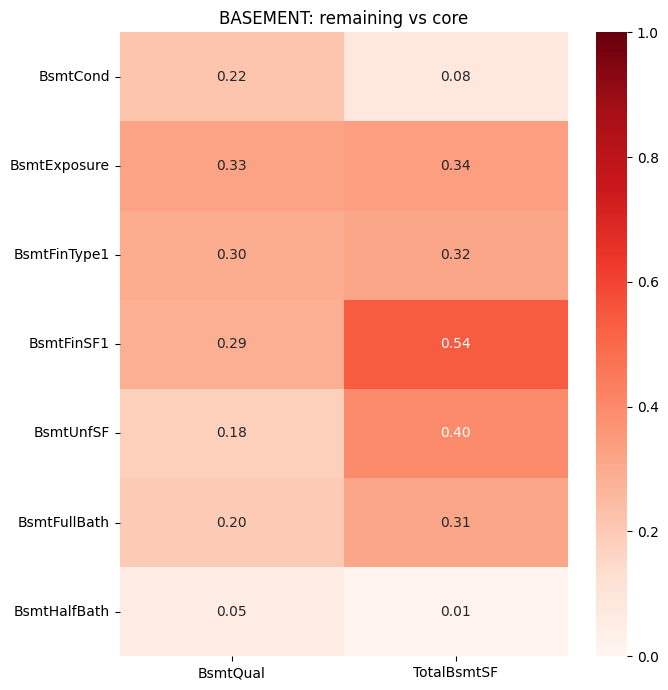


===== BASEMENT - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
33,BsmtFinSF1,0.375752,0.310490,0.166833,0.323440,0.695898,BsmtFinType1
32,BsmtFinType1,0.332294,0.356270,0.152053,0.323440,0.695898,BsmtFinSF1
36,BsmtUnfSF,0.209785,0.172766,0.123753,0.079148,0.496833,BsmtFinSF1
31,BsmtExposure,0.339268,0.317137,0.058802,0.679604,0.362122,BsmtFinSF1
46,BsmtFullBath,0.249521,0.241236,0.027136,0.590563,0.653736,BsmtFinSF1
30,BsmtCond,0.209834,0.199141,0.020888,0.920091,0.232881,YearBuilt
47,BsmtHalfBath,0.004404,0.012977,0.001657,0.944444,0.145243,BsmtFullBath


In [71]:
# ============================================================
# BASEMENT
# ============================================================

basement_analysis = analyze_feature_group(
    group_name='basement',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [72]:
basement_keep = [
    'TotalBsmtSF',
    'BsmtQual',
    'BsmtFinSF1',
    'BsmtFinType1',
    'BsmtUnfSF',
    'BsmtExposure'
]

basement_drop = [
    'BsmtFullBath',
    'BsmtCond',
    'BsmtFinType2',
    'BsmtFinSF2',
    'BsmtHalfBath'
]

===== UTILITIES - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
39,HeatingQC,0.473535,0.490669,0.152115,0.506849,0.544300,YearRemodAdd,False,False
40,CentralAir,0.357125,0.316713,0.066431,0.931507,0.454996,Heating,False,False
41,Electrical,0.306010,0.304030,0.054293,0.908676,0.408490,CentralAir,False,False
38,Heating,0.162131,0.116455,0.017790,0.977169,0.454996,CentralAir,False,False
8,Utilities,0.013215,0.017716,0.009382,0.999239,0.119095,SaleType,False,True


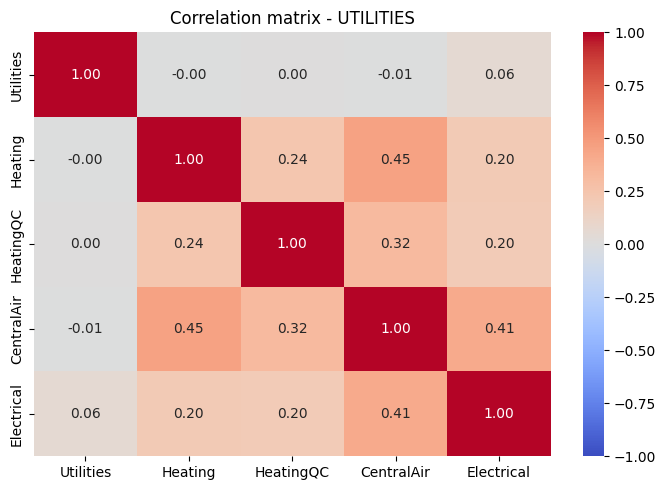

CORE:
[]

REMAINING:
['Heating', 'HeatingQC', 'CentralAir', 'Electrical']

Remaining vs core correlation matrix cannot be created.
No CORE features in this group.

===== UTILITIES - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
39,HeatingQC,0.473535,0.490669,0.152115,0.506849,0.544300,YearRemodAdd
40,CentralAir,0.357125,0.316713,0.066431,0.931507,0.454996,Heating
41,Electrical,0.306010,0.304030,0.054293,0.908676,0.408490,CentralAir
38,Heating,0.162131,0.116455,0.017790,0.977169,0.454996,CentralAir


In [73]:
# ============================================================
# UTILITIES / INSTALLATIONS
# ============================================================

utilities_analysis = analyze_feature_group(
    group_name='utilities',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [74]:
utilities_keep = [
    'HeatingQC',
    'CentralAir',
    'Electrical'
]

utilities_drop = [
    'Heating',
    'Utilities'
]

===== INTERIOR - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
45,GrLivArea,0.726052,0.727190,0.469402,0.014460,0.824856,TotRmsAbvGrd,True,False
52,KitchenQual,0.667120,0.674137,0.326124,0.505327,0.717513,ExterQual,True,False
42,1stFlrSF,0.613096,0.581551,0.301809,0.016743,0.774033,TotalBsmtSF,True,False
48,FullBath,0.585048,0.622560,0.264839,0.525114,0.643716,GrLivArea,True,False
53,TotRmsAbvGrd,0.531705,0.525965,0.209352,0.274734,0.824856,GrLivArea,True,False
43,2ndFlrSF,0.311080,0.287537,0.195947,0.563927,0.663684,GrLivArea,False,False
49,HalfBath,0.311636,0.339369,0.084908,0.623288,0.607204,2ndFlrSF,False,False
50,BedroomAbvGr,0.202220,0.225777,0.064399,0.547945,0.678333,TotRmsAbvGrd,False,False
51,KitchenAbvGr,0.150588,0.168163,0.026025,0.954338,0.636570,BldgType,False,False
54,Functional,0.142087,0.142397,0.022229,0.930746,0.170949,OverallQual,False,False


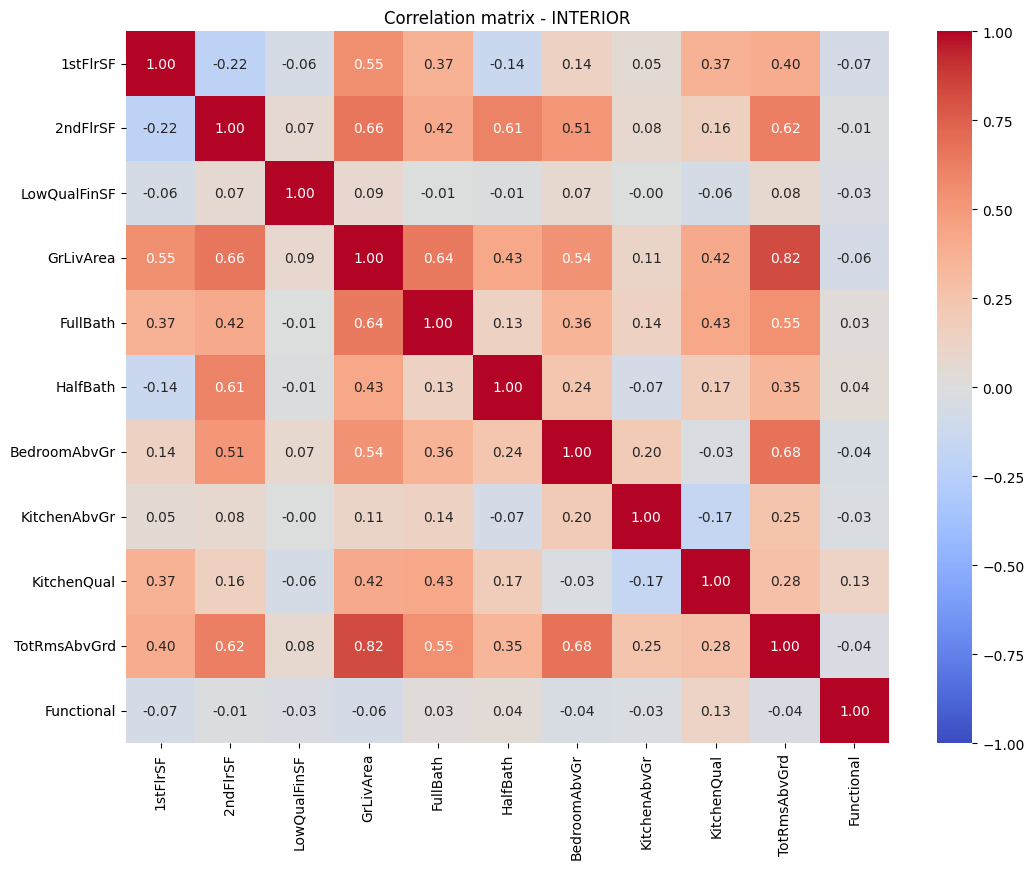

CORE:
['1stFlrSF', 'GrLivArea', 'FullBath', 'KitchenQual', 'TotRmsAbvGrd']

REMAINING:
['2ndFlrSF', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'Functional']

===== INTERIOR - REMAINING VS CORE =====


,1stFlrSF,GrLivArea,FullBath,KitchenQual,TotRmsAbvGrd
2ndFlrSF,0.215120,0.663684,0.416158,0.155927,0.621558
HalfBath,0.135747,0.428754,0.134797,0.172577,0.346839
BedroomAbvGr,0.144040,0.537334,0.356986,0.030988,0.678333
KitchenAbvGr,0.050771,0.110955,0.140103,0.168801,0.251392
Functional,0.069123,0.062718,0.028389,0.127458,0.037495


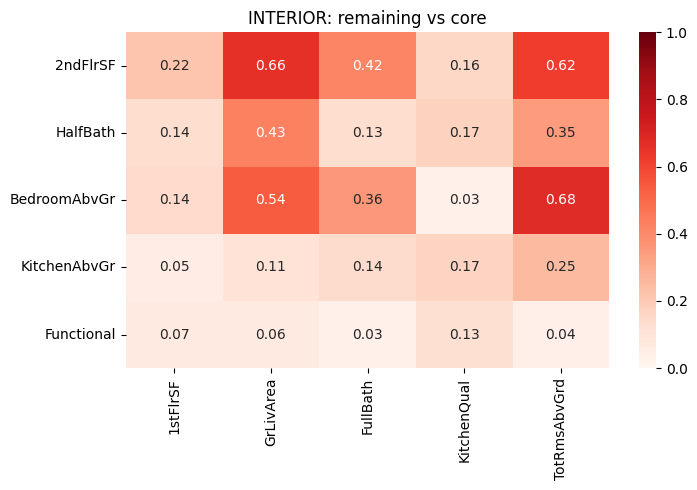


===== INTERIOR - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
43,2ndFlrSF,0.311080,0.287537,0.195947,0.563927,0.663684,GrLivArea
49,HalfBath,0.311636,0.339369,0.084908,0.623288,0.607204,2ndFlrSF
50,BedroomAbvGr,0.202220,0.225777,0.064399,0.547945,0.678333,TotRmsAbvGrd
51,KitchenAbvGr,0.150588,0.168163,0.026025,0.954338,0.636570,BldgType
54,Functional,0.142087,0.142397,0.022229,0.930746,0.170949,OverallQual


In [75]:
# ============================================================
# SIZE / INTERIOR
# ============================================================

interior_analysis = analyze_feature_group(
    group_name='interior',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [76]:
interior_keep = [
    'GrLivArea',
    'KitchenQual',
    '1stFlrSF',
    'FullBath',
    'TotRmsAbvGrd',
    '2ndFlrSF',
    'HalfBath'
]

interior_drop = [
    'BedroomAbvGr',
    'KitchenAbvGr',
    'Functional',
    'LowQualFinSF'
]

===== FIREPLACE - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
56,FireplaceQu,0.551607,0.542329,0.232722,0.472603,0.862496,Fireplaces,True,False
55,Fireplaces,0.492053,0.524687,0.172795,0.472603,0.862496,FireplaceQu,False,False


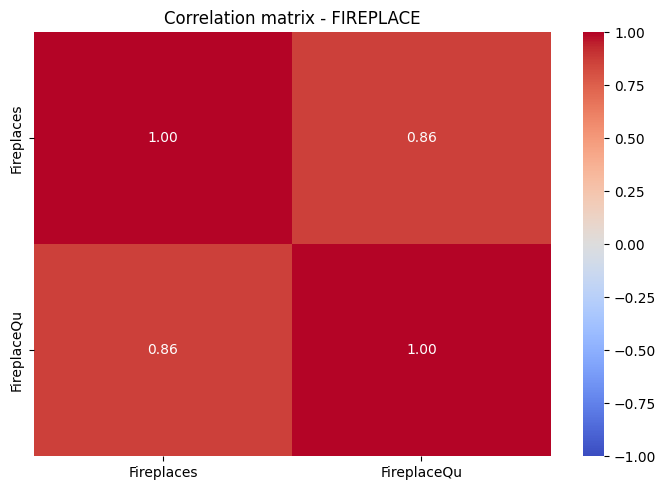

CORE:
['FireplaceQu']

REMAINING:
['Fireplaces']

===== FIREPLACE - REMAINING VS CORE =====


,FireplaceQu
Fireplaces,0.862496


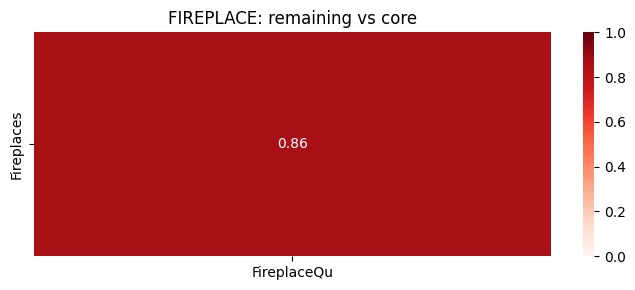


===== FIREPLACE - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
55,Fireplaces,0.492053,0.524687,0.172795,0.472603,0.862496,FireplaceQu


In [77]:
# ============================================================
# FIREPLACE
# ============================================================

fireplace_analysis = analyze_feature_group(
    group_name='fireplace',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [78]:
fireplace_keep = [
    'FireplaceQu'
]

fireplace_drop = [
    'Fireplaces'
]

===== GARAGE - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
60,GarageCars,0.691922,0.699425,0.384193,0.563166,0.883530,GarageArea,True,False
61,GarageArea,0.655901,0.653542,0.367417,0.056317,0.883530,GarageCars,True,False
58,GarageYrBlt,0.500560,0.563070,0.254485,0.057078,0.781937,YearBuilt,True,False
59,GarageFinish,0.569924,0.613495,0.236825,0.468037,0.595149,YearBuilt,True,False
57,GarageType,0.420646,0.466929,0.125635,0.651446,0.520332,YearBuilt,False,False
64,PavedDrive,0.316746,0.292672,0.052219,0.914003,0.428491,YearBuilt,False,False
63,GarageCond,0.155409,0.166377,0.017888,0.961948,0.645721,GarageQual,False,False
62,GarageQual,0.182228,0.197227,0.010884,0.952816,0.645721,GarageCond,False,False


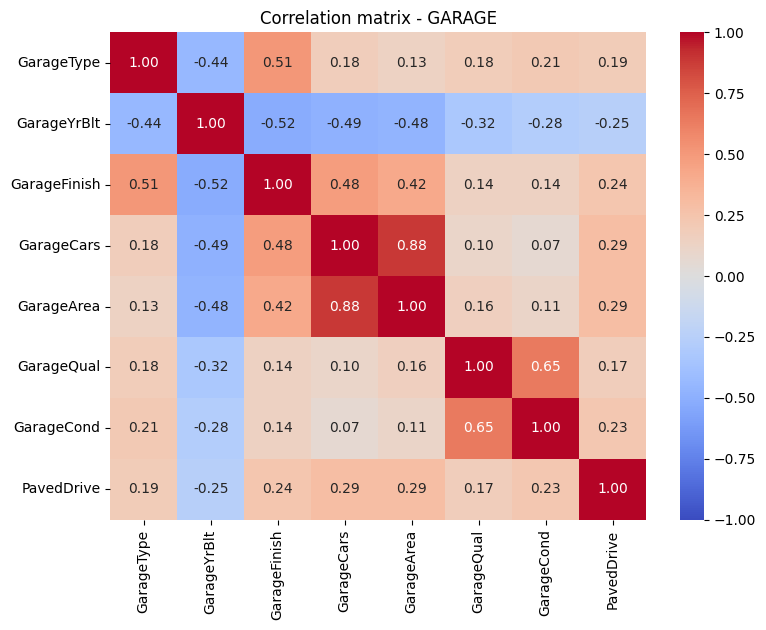

CORE:
['GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea']

REMAINING:
['GarageType', 'GarageQual', 'GarageCond', 'PavedDrive']

===== GARAGE - REMAINING VS CORE =====


,GarageYrBlt,GarageFinish,GarageCars,GarageArea
GarageType,0.442193,0.512070,0.176612,0.132935
GarageQual,0.324446,0.142607,0.103729,0.156490
GarageCond,0.276097,0.140649,0.066630,0.114455
PavedDrive,0.254158,0.238301,0.294945,0.293956


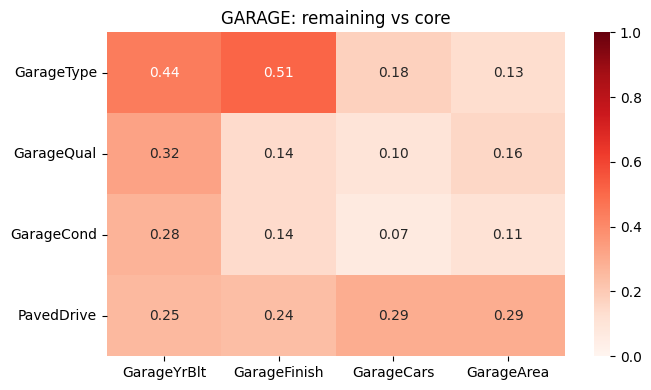


===== GARAGE - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
57,GarageType,0.420646,0.466929,0.125635,0.651446,0.520332,YearBuilt
64,PavedDrive,0.316746,0.292672,0.052219,0.914003,0.428491,YearBuilt
63,GarageCond,0.155409,0.166377,0.017888,0.961948,0.645721,GarageQual
62,GarageQual,0.182228,0.197227,0.010884,0.952816,0.645721,GarageCond


In [79]:
# ============================================================
# GARAGE
# ============================================================

garage_analysis = analyze_feature_group(
    group_name='garage',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [80]:
garage_keep = [
    'GarageCars',
    'GarageYrBlt',
    'GarageFinish',
    'GarageType',
    'PavedDrive'
]

garage_drop = [
    'GarageArea',
    'GarageQual',
    'GarageCond'
]

===== OUTDOOR - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
66,OpenPorchSF,0.311436,0.469672,0.163146,0.446728,0.317592,GrLivArea,False,False
65,WoodDeckSF,0.332111,0.356710,0.111999,0.524353,0.263919,BsmtQual,False,False
67,EnclosedPorch,0.225367,0.235491,0.026697,0.857686,0.462075,YearBuilt,False,False
72,Fence,0.142595,0.180215,0.026474,0.814307,0.221023,ExterQual,False,False
68,3SsnPorch,0.059832,0.069377,0.009637,0.984779,0.101767,Condition1,False,True
69,ScreenPorch,0.108869,0.107468,0.008230,0.921613,0.198976,Fireplaces,False,False
70,PoolArea,0.038471,0.046682,0.000657,0.995434,0.988232,PoolQC,False,True
71,PoolQC,0.036888,0.046647,0.000283,0.995434,0.988232,PoolArea,False,True


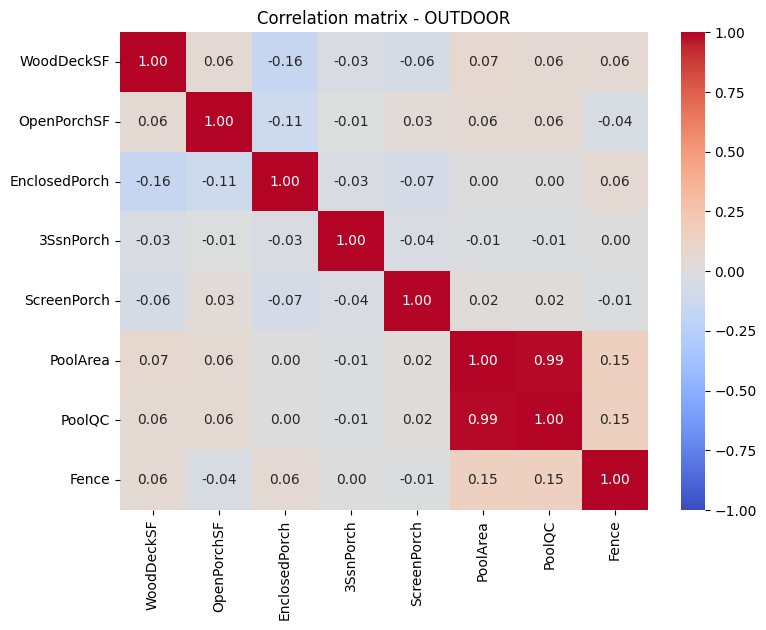

CORE:
[]

REMAINING:
['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', 'ScreenPorch', 'Fence']

Remaining vs core correlation matrix cannot be created.
No CORE features in this group.

===== OUTDOOR - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
66,OpenPorchSF,0.311436,0.469672,0.163146,0.446728,0.317592,GrLivArea
65,WoodDeckSF,0.332111,0.356710,0.111999,0.524353,0.263919,BsmtQual
67,EnclosedPorch,0.225367,0.235491,0.026697,0.857686,0.462075,YearBuilt
72,Fence,0.142595,0.180215,0.026474,0.814307,0.221023,ExterQual
69,ScreenPorch,0.108869,0.107468,0.008230,0.921613,0.198976,Fireplaces


In [81]:
# ============================================================
# OUTDOOR / AMENITIES
# ============================================================

outdoor_analysis = analyze_feature_group(
    group_name='outdoor',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [82]:
outdoor_keep = [
    'OpenPorchSF',
    'WoodDeckSF'
]

outdoor_drop = [
    'EnclosedPorch',
    'Fence',
    'ScreenPorch',
    '3SsnPorch',
    'PoolArea',
    'PoolQC'
]

===== MISC - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
73,MiscFeature,0.070153,0.062734,0.006995,0.961187,0.937721,MiscVal,False,True
74,MiscVal,0.069600,0.060346,0.000770,0.961948,0.937721,MiscFeature,False,True


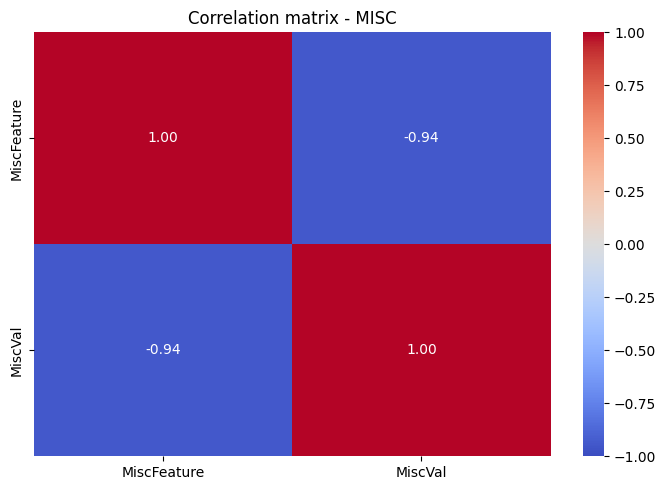

CORE:
[]

REMAINING:
[]

Remaining vs core correlation matrix cannot be created.
No CORE features in this group.
No REMAINING features in this group.

===== MISC - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with


In [83]:
# ============================================================
# MISC
# ============================================================

misc_analysis = analyze_feature_group(
    group_name='misc',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

===== SALE - GENERAL REPORT =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with,is_core,is_drop_candidate
76,SaleType,0.267824,0.294081,0.075965,0.870624,0.486673,SaleCondition,False,False
77,SaleCondition,0.296165,0.321132,0.075687,0.828006,0.486673,SaleType,False,False
75,MoSold,0.055795,0.067521,0.000000,0.168189,0.087410,LandContour,False,False


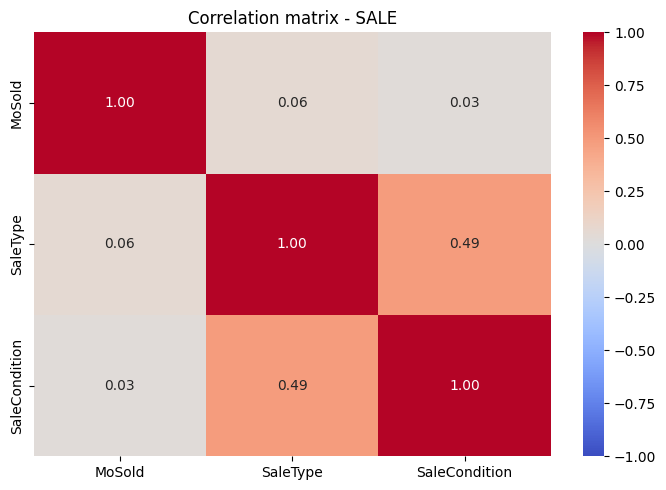

CORE:
[]

REMAINING:
['MoSold', 'SaleType', 'SaleCondition']

Remaining vs core correlation matrix cannot be created.
No CORE features in this group.

===== SALE - REMAINING FEATURES =====


,feature,Pearson,Spearman,mutual_information,dominant_share,max_abs_corr,most_correlated_with
76,SaleType,0.267824,0.294081,0.075965,0.870624,0.486673,SaleCondition
77,SaleCondition,0.296165,0.321132,0.075687,0.828006,0.486673,SaleType
75,MoSold,0.055795,0.067521,0.000000,0.168189,0.087410,LandContour


In [84]:
# ============================================================
# SALE
# ============================================================

sale_analysis = analyze_feature_group(
    group_name='sale',
    feature_groups=feature_groups,
    feature_report=feature_report,
    X_train=X_train,
    core_features=core_features,
    remaining_features=remaining_features,
    drop_candidate=drop_candidate
)

In [85]:
sale_keep = [
    'SaleType',
    'SaleCondition'
]

sale_drop = [
    'MoSold'
]

In [86]:
features_to_drop = (
    drop_candidate
    + location_drop
    + building_type_drop
    + exterior_drop
    + basement_drop
    + utilities_drop
    + interior_drop
    + fireplace_drop
    + garage_drop
    + outdoor_drop
    + sale_drop
)
features_to_drop = list(set(features_to_drop))

In [87]:
selected_features = [
    feature
    for feature in X_train.columns
    if feature not in features_to_drop
]

print('Original number of features:', X_train.shape[1])
print('Selected features:', len(selected_features))
print('Removed features:', len(features_to_drop))

Original number of features: 78
Selected features: 42
Removed features: 36


In [88]:
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

Dalej trzeba zobaczyć czy nie ma zbyt dużych korelacji już w finalnej grupie wybranyh cech i dokonać jakiejś ostatecznej analizy

In [89]:
selected_corr = X_train_selected.corr().abs()

upper = selected_corr.where(
    np.triu(
        np.ones(selected_corr.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper
    .stack()
    .sort_values(ascending=False)
    .reset_index()
)

high_corr_pairs.columns = [
    'feature_1',
    'feature_2',
    'correlation'
]

high_corr_pairs[
    high_corr_pairs['correlation'] >= 0.80
]

,feature_1,feature_2,correlation
0,GrLivArea,TotRmsAbvGrd,0.824856


In [90]:
features_to_check = np.unique(
    high_corr_pairs.loc[
        high_corr_pairs['correlation'] >= 0.8,
        ['feature_1', 'feature_2']
    ].values
)

feature_report[
    feature_report['feature'].isin(features_to_check)
][
    [
        'feature',
        'Pearson',
        'Spearman',
        'mutual_information',
        'dominant_share'
    ]
].sort_values(
    'mutual_information',
    ascending=False
)

,feature,Pearson,Spearman,mutual_information,dominant_share
45,GrLivArea,0.726052,0.727190,0.469402,0.014460
53,TotRmsAbvGrd,0.531705,0.525965,0.209352,0.274734


# Modelling

In [91]:
from sklearn.model_selection import KFold, cross_validate

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from xgboost import XGBRegressor

In [92]:
RANDOM_STATE=20260977

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [93]:
models = {
    'Linear Regression': LinearRegression(),

    'Random Forest': RandomForestRegressor(
        random_state=RANDOM_STATE
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),

    'XGBoost': XGBRegressor(
        objective='reg:squarederror',
        random_state=RANDOM_STATE
    )
}

In [94]:
def evaluate_model(model, X, y, cv):
  scoring = {
      'rmse': 'neg_root_mean_squared_error',
      'mae': 'neg_mean_absolute_error',
      'r2': 'r2'
  }

  scores = cross_validate(
      estimator = model,
      X=X,
      y=y,
      cv=cv,
      scoring=scoring,
      return_train_score=True,
      n_jobs=-1
  )

  results = pd.DataFrame({
      'train_rmse': -scores['train_rmse'],
      'cv_rmse': -scores['test_rmse'],
      'train_mae': -scores['train_mae'],
      'cv_mae': -scores['test_mae'],
      'train_r2': scores['train_r2'],
      'cv_r2': scores['test_r2'],
      'fit_time': scores['fit_time']
  })
  return results

In [95]:
cv_results = {}

for name,model in models.items():
  cv_results[name] = evaluate_model(
      model=model,
      X=X_train_selected,
      y=y_train,
      cv=cv
  )

In [96]:
baseline_summary = []

for name,results in cv_results.items():
  baseline_summary.append({
      'model': name,

      'train_rmse': results['train_rmse'].mean(),
      'cv_rmse': results['cv_rmse'].mean(),
      'cv_rmse_std': results['cv_rmse'].std(),

      'cv_mae': results['cv_mae'].mean(),
      'cv_r2': results['cv_r2'].mean(),

      'fit_time': results['fit_time'].mean()
  })

baseline_summary=pd.DataFrame(baseline_summary).sort_values(
    by='cv_rmse',
    ascending=True
).reset_index(drop=True)


In [97]:
baseline_summary['rmse_gap'] = (
    baseline_summary['cv_rmse']
    - baseline_summary['train_rmse']
)
baseline_summary

,model,train_rmse,cv_rmse,cv_rmse_std,cv_mae,cv_r2,fit_time,rmse_gap
0,Gradient Boosting,0.076686,0.126000,0.014121,0.086593,0.899776,0.824639,0.049314
1,Linear Regression,0.123691,0.133684,0.016922,0.087958,0.885109,0.010831,0.009992
2,XGBoost,0.004396,0.139833,0.012936,0.098966,0.877198,0.621051,0.135437
3,Random Forest,0.054330,0.140877,0.010704,0.094946,0.875402,2.641886,0.086548


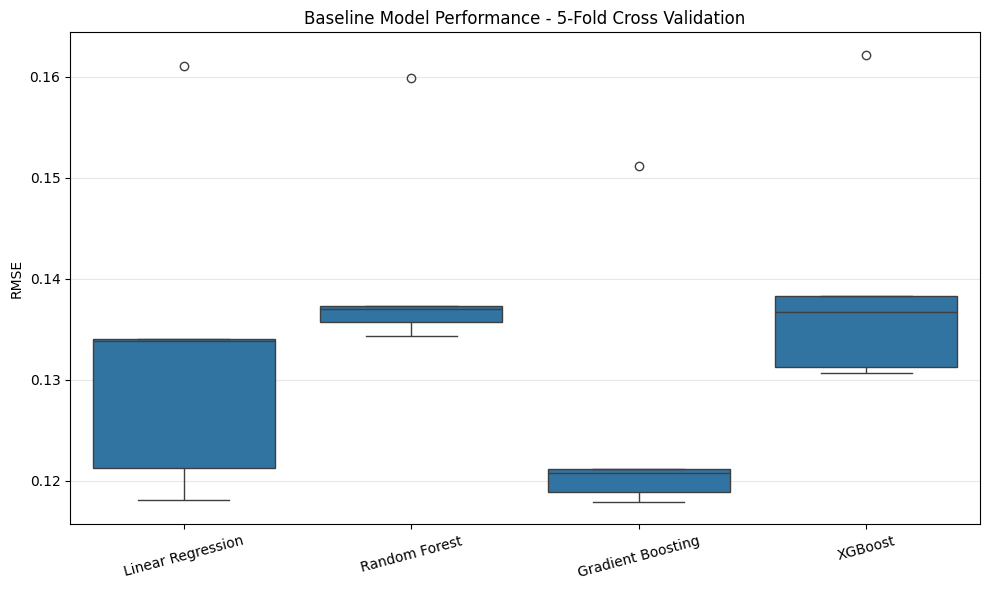

In [98]:
plot_data = []

for name, results in cv_results.items():

    for rmse in results['cv_rmse']:

        plot_data.append({
            'Model': name,
            'RMSE': rmse
        })

plot_data = pd.DataFrame(plot_data)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_data,
    x='Model',
    y='RMSE'
)

plt.title(
    'Baseline Model Performance - 5-Fold Cross Validation'
)

plt.xlabel('')
plt.ylabel('RMSE')

plt.xticks(rotation=15)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

Gradient Boosting achieved the best baseline cross-validation performance with the lowest mean RMSE and highest R². Linear Regression provided a strong and stable benchmark with only a small train-validation performance gap. Random Forest showed substantial overfitting while providing the weakest validation performance. XGBoost also exhibited severe overfitting under its default configuration, suggesting that regularization and complexity control may substantially improve its generalization. Therefore, Gradient Boosting and XGBoost were selected for hyperparameter optimization.

# Optimization

In [99]:
pip install optuna

Note: you may need to restart the kernel to use updated packages.


In [100]:
import optuna
from sklearn.model_selection import cross_val_score
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

def get_cv_rmse(model, X, y, cv):

    scores = cross_val_score(
        model,
        X,
        y,
        scoring='neg_root_mean_squared_error',
        cv=cv,
        n_jobs=-1
    )

    return -scores.mean()

In [101]:
def objective_gbm(trial):

    params = {
        'n_estimators': trial.suggest_int(
            'n_estimators',
            100,
            500
        ),

        'learning_rate': trial.suggest_float(
            'learning_rate',
            0.01,
            0.2,
            log=True
        ),

        'max_depth': trial.suggest_int(
            'max_depth',
            2,
            5
        ),

        'min_samples_split': trial.suggest_int(
            'min_samples_split',
            2,
            20
        ),

        'min_samples_leaf': trial.suggest_int(
            'min_samples_leaf',
            1,
            20
        ),

        'subsample': trial.suggest_float(
            'subsample',
            0.6,
            1.0
        ),

        'max_features': trial.suggest_float(
            'max_features',
            0.5,
            1.0
        ),

        'random_state': RANDOM_STATE
    }

    model = GradientBoostingRegressor(
        **params
    )

    return get_cv_rmse(
        model=model,
        X=X_train_selected,
        y=y_train,
        cv=cv
    )

In [102]:
sampler_gbm = TPESampler(
    seed=RANDOM_STATE
)

study_gbm = optuna.create_study(
    direction='minimize',
    sampler=sampler_gbm
)

study_gbm.optimize(
    objective_gbm,
    n_trials=50
)

In [103]:
print(
    'Best GBM CV RMSE:',
    study_gbm.best_value
)

print(
    '\nBest GBM parameters:'
)

study_gbm.best_params

Best GBM CV RMSE: 0.1223453098605829

Best GBM parameters:


{'n_estimators': 210,
 'learning_rate': 0.07509372469742102,
 'max_depth': 5,
 'min_samples_split': 19,
 'min_samples_leaf': 2,
 'subsample': 0.9268142134386899,
 'max_features': 0.6576124050638852}

In [104]:
def objective_xgb(trial):

    params = {
        'n_estimators': trial.suggest_int(
            'n_estimators',
            200,
            1500
        ),

        'learning_rate': trial.suggest_float(
            'learning_rate',
            0.01,
            0.15,
            log=True
        ),

        'max_depth': trial.suggest_int(
            'max_depth',
            2,
            6
        ),

        'min_child_weight': trial.suggest_int(
            'min_child_weight',
            1,
            15
        ),

        'subsample': trial.suggest_float(
            'subsample',
            0.6,
            1.0
        ),

        'colsample_bytree': trial.suggest_float(
            'colsample_bytree',
            0.6,
            1.0
        ),

        'gamma': trial.suggest_float(
            'gamma',
            0.0,
            0.3
        ),

        'reg_alpha': trial.suggest_float(
            'reg_alpha',
            1e-5,
            1.0,
            log=True
        ),

        'reg_lambda': trial.suggest_float(
            'reg_lambda',
            1e-2,
            20.0,
            log=True
        ),

        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',

        'tree_method': 'hist',

        'random_state': RANDOM_STATE,
        'n_jobs': 1,
        'verbosity': 0
    }

    model = XGBRegressor(
        **params
    )

    return get_cv_rmse(
        model=model,
        X=X_train_selected,
        y=y_train,
        cv=cv
    )

In [105]:
sampler_xgb = TPESampler(
    seed=RANDOM_STATE
)

study_xgb = optuna.create_study(
    direction='minimize',
    sampler=sampler_xgb
)

study_xgb.optimize(
    objective_xgb,
    n_trials=50
)

In [106]:
print(
    'Best XGBoost CV RMSE:',
    study_xgb.best_value
)

print(
    '\nBest XGBoost parameters:'
)

study_xgb.best_params

Best XGBoost CV RMSE: 0.12250454436352812

Best XGBoost parameters:


{'n_estimators': 1478,
 'learning_rate': 0.01943989457098198,
 'max_depth': 6,
 'min_child_weight': 1,
 'subsample': 0.6195621734644178,
 'colsample_bytree': 0.8371966286848634,
 'gamma': 0.051941730223365734,
 'reg_alpha': 0.13278314561505644,
 'reg_lambda': 1.3408234323482282}

In [107]:
final_models = {

    'Linear Regression': LinearRegression(),

    'Gradient Boosting': GradientBoostingRegressor(
        **study_gbm.best_params,
        random_state=RANDOM_STATE
    ),

    'XGBoost': XGBRegressor(
        **study_xgb.best_params,
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=0
    )
}

In [108]:
final_cv_results = {}

for name, model in final_models.items():

    print(f'Evaluating: {name}')

    final_cv_results[name] = evaluate_model(
        model=model,
        X=X_train_selected,
        y=y_train,
        cv=cv
    )

Evaluating: Linear Regression
Evaluating: Gradient Boosting
Evaluating: XGBoost


In [109]:
final_rows = []

for name, results in final_cv_results.items():

    final_rows.append({
        'model': name,

        'train_rmse':
            results['train_rmse'].mean(),

        'cv_rmse':
            results['cv_rmse'].mean(),

        'cv_rmse_std':
            results['cv_rmse'].std(),

        'cv_mae':
            results['cv_mae'].mean(),

        'cv_r2':
            results['cv_r2'].mean(),

        'fit_time':
            results['fit_time'].mean()
    })


final_summary = pd.DataFrame(final_rows)

final_summary['rmse_gap'] = (
    final_summary['cv_rmse']
    - final_summary['train_rmse']
)

final_summary = (
    final_summary
    .sort_values('cv_rmse')
    .reset_index(drop=True)
)

final_summary

,model,train_rmse,cv_rmse,cv_rmse_std,cv_mae,cv_r2,fit_time,rmse_gap
0,Gradient Boosting,0.032171,0.122345,0.012552,0.085125,0.905766,1.802467,0.090174
1,XGBoost,0.073792,0.122505,0.010103,0.083541,0.905742,1.464340,0.048712
2,Linear Regression,0.123691,0.133684,0.016922,0.087958,0.885109,0.006610,0.009992


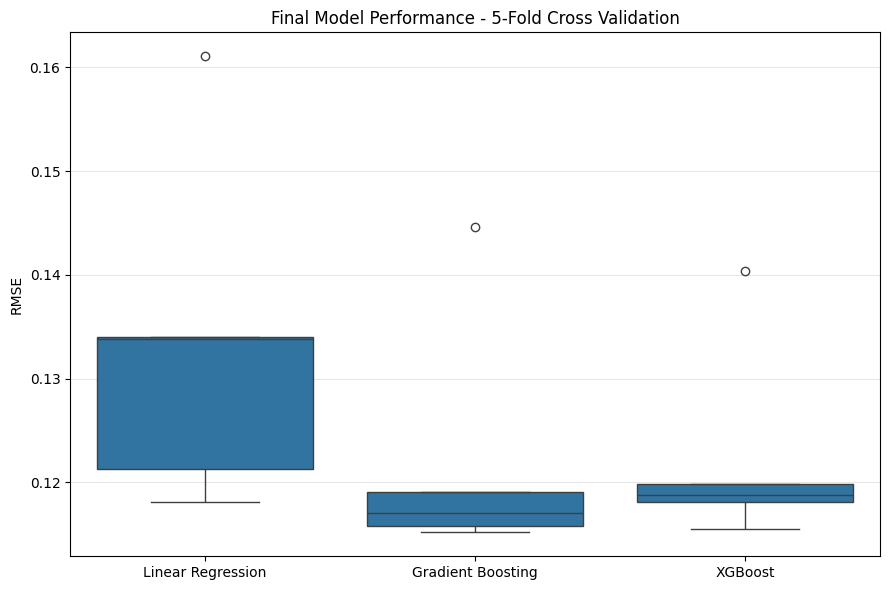

In [110]:
final_plot_data = []

for name, results in final_cv_results.items():

    for rmse in results['cv_rmse']:

        final_plot_data.append({
            'Model': name,
            'RMSE': rmse
        })


final_plot_data = pd.DataFrame(
    final_plot_data
)

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=final_plot_data,
    x='Model',
    y='RMSE'
)

plt.title(
    'Final Model Performance - 5-Fold Cross Validation'
)

plt.xlabel('')
plt.ylabel('RMSE')

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

After hyperparameter optimization, XGBoost achieved the lowest mean cross-validation RMSE and the highest R² among the evaluated models. Hyperparameter tuning also substantially reduced the train-validation gap observed in the baseline XGBoost model, indicating improved generalization. Gradient Boosting produced comparable and slightly more stable results across folds, while Linear Regression remained a strong low-variance benchmark. Based on the cross-validation results, XGBoost was selected as the final model.

In [111]:
final_model = final_models['XGBoost']

In [112]:
final_model.fit(
    X_train_selected,
    y_train
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8371966286848634, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric='rmse', feature_types=None, feature_weights=None,
             gamma=0.051941730223365734, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.01943989457098198,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=1, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1478, n_jobs=1,
             num_parallel_tree=None, ...)

In [113]:
y_pred = final_model.predict(
    X_test_selected
)

In [114]:
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score
)

test_rmse = root_mean_squared_error(
    y_test,
    y_pred
)

test_mae = mean_absolute_error(
    y_test,
    y_pred
)

test_r2 = r2_score(
    y_test,
    y_pred
)

In [115]:
final_test_results = pd.DataFrame({
    'model': ['XGBoost'],
    'test_rmse': [test_rmse],
    'test_mae': [test_mae],
    'test_r2': [test_r2]
})

final_test_results

,model,test_rmse,test_mae,test_r2
0,XGBoost,0.132142,0.092065,0.872481


In [116]:
xgb_cv_rmse = final_summary.loc[
    final_summary['model'] == 'XGBoost',
    'cv_rmse'
].iloc[0]

xgb_cv_std = final_summary.loc[
    final_summary['model'] == 'XGBoost',
    'cv_rmse_std'
].iloc[0]

final_evaluation = pd.DataFrame({
    'CV RMSE': [xgb_cv_rmse],
    'CV RMSE STD': [xgb_cv_std],
    'Test RMSE': [test_rmse],
    'Test MAE': [test_mae],
    'Test R2': [test_r2]
})

final_evaluation

,CV RMSE,CV RMSE STD,Test RMSE,Test MAE,Test R2
0,0.122505,0.010103,0.132142,0.092065,0.872481


# Final Model Evaluation

After preprocessing, feature selection, model comparison, and hyperparameter optimization with Optuna, XGBoost was selected as the final model.

The optimized model achieved a **test RMSE of 0.130** and an **R² of 0.876**, meaning that it explains approximately 87.6% of the variation in the target variable on previously unseen data.

Its test RMSE was also reasonably close to the cross-validation result of **0.121 ± 0.013**. The relatively small difference between cross-validation and test performance suggests that the model did not substantially overfit the training data and that the validation procedure provided a useful estimate of its out-of-sample performance.

More importantly, the project shows that predictive performance was not driven by model complexity alone. Careful preprocessing, examination of feature distributions, removal of redundant or weak predictors, and systematic hyperparameter optimization all contributed to the final modelling pipeline.

Overall, the final XGBoost model provides a strong balance between predictive accuracy and generalization. The remaining prediction error also indicates that house prices are influenced by complex relationships that cannot be fully captured by the available features, leaving room for further improvements through additional feature engineering, alternative ensemble approaches, or model stacking.